Fig.1a S2

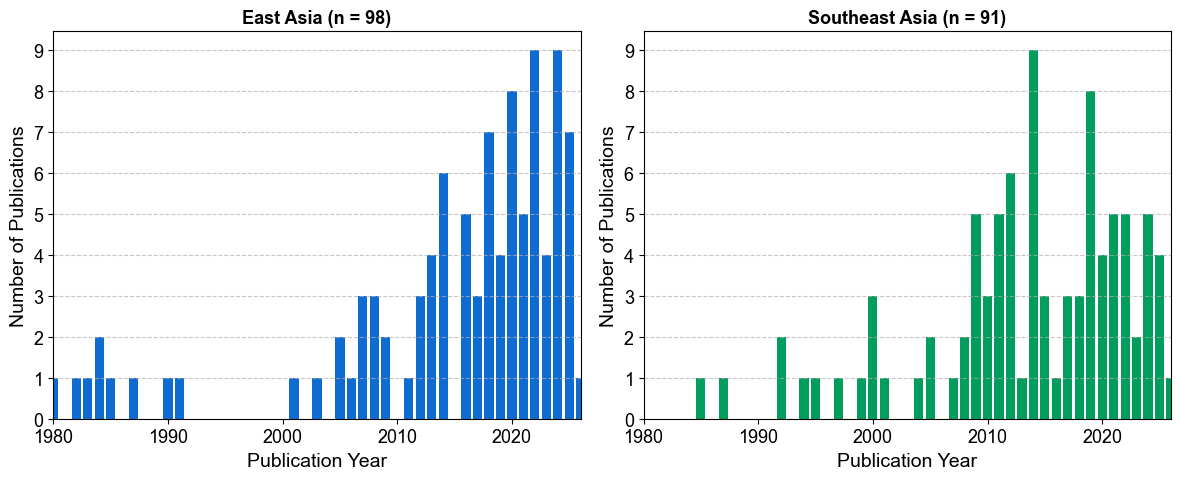

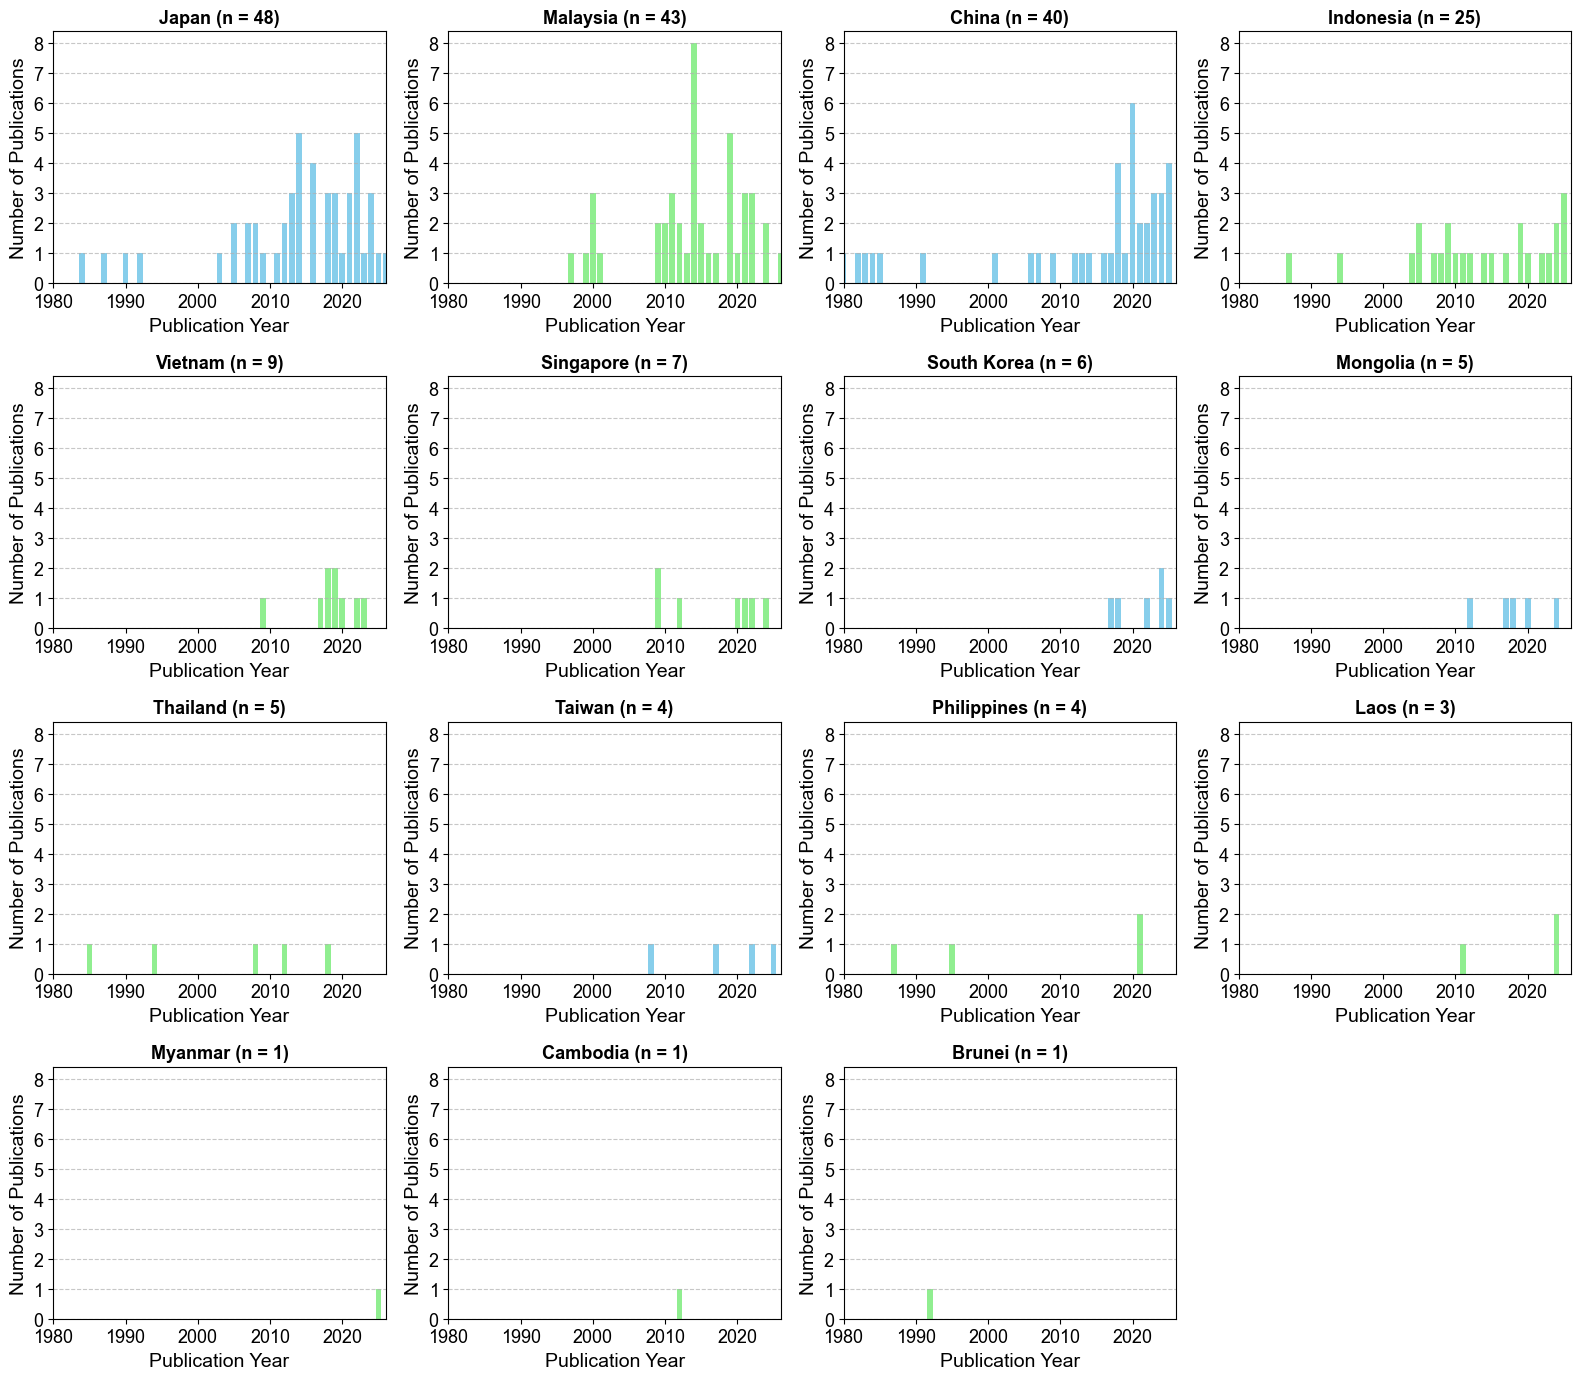

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.family'] = 'Arial' #Setting font
plt.rcParams['font.size'] = 13

# Load the data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)




# --- 1. Figure for Regions
target_regions = ['Region_East Asia', 'Region_Southeast Asia']
regions_present = [col for col in target_regions if col in df.columns]

# Calculate total and max Y for regions 
region_totals = {}
max_y_region = 0
for col in regions_present:
    subset = df[df[col] == 1]
    if len(subset) > 0:
        region_totals[col] = len(subset)
        max_val = subset['Publication Year'].value_counts().max()
        if max_val > max_y_region:
            max_y_region = max_val

fig1, axes1 = plt.subplots(1, len(regions_present), figsize=(12, 5))
if len(regions_present) == 1:
    axes1 = [axes1]

for ax, col in zip(axes1, regions_present):
    region_name = col.replace('Region_', '')
    subset = df[df[col] == 1]
    yearly_counts = subset['Publication Year'].value_counts().sort_index()
    total_count = region_totals.get(col, 0)
    
# Set color for regions
    if 'East Asia' in region_name:
        bar_color = '#0E6BD1'   
    elif 'Southeast Asia' in region_name:
        bar_color = '#009D5C'  
    else:
        bar_color = 'gray'
        
    if len(subset) > 0:
        ax.bar(yearly_counts.index, yearly_counts.values, color=bar_color)
    
    ax.set_title(f'{region_name} (n = {total_count})', fontsize=13, fontweight='bold')
    ax.set_xlabel('Publication Year', fontsize=14)
    ax.set_ylabel('Number of Publications', fontsize=14)
    
    ax.set_xlim(1980, 2026)
    if max_y_region > 0:
        ax.set_ylim(0, max_y_region * 1.05)
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


# --- 2. Figure for Countries 
country_cols = [col for col in df.columns if str(col).startswith('Country_')]

country_totals = {}
for col in country_cols:
    subset = df[df[col] == 1]
    if len(subset) > 0:
        country_totals[col] = len(subset)

sorted_country_cols = sorted(country_totals.items(), key=lambda item: item[1], reverse=True)

max_y_country = 0
for col, total in sorted_country_cols:
    subset = df[df[col] == 1]
    max_val = subset['Publication Year'].value_counts().max()
    if max_val > max_y_country:
        max_y_country = max_val

n_countries = len(sorted_country_cols)
cols_per_row = 4
n_rows = math.ceil(n_countries / cols_per_row)

fig2, axes2 = plt.subplots(n_rows, cols_per_row, figsize=(16, 3.5 * n_rows))
axes2 = axes2.flatten() 

# Define which region each country belongs to
ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

for i, (col, total_count) in enumerate(sorted_country_cols):
    country_name = col.replace('Country_', '')
    subset = df[df[col] == 1]
    yearly_counts = subset['Publication Year'].value_counts().sort_index()

    
    # Set color for countries
    if country_name in ea_countries:
        bar_color = 'skyblue'     
    elif country_name in sea_countries:
        bar_color = 'lightgreen'  
    else:
        bar_color = 'lightgray'
        
    ax = axes2[i]
    ax.bar(yearly_counts.index, yearly_counts.values, color=bar_color)
        
    ax.set_title(f'{country_name} (n = {total_count})', fontsize=13, fontweight='bold')
    ax.set_xlabel('Publication Year', fontsize=14)
    ax.set_ylabel('Number of Publications', fontsize=14)
    
    ax.set_xlim(1980, 2026)
    if max_y_country > 0:
        ax.set_ylim(0, max_y_country * 1.05)
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)

for j in range(i + 1, len(axes2)):
    axes2[j].set_visible(False)

plt.tight_layout()
plt.show()


Fig. S3

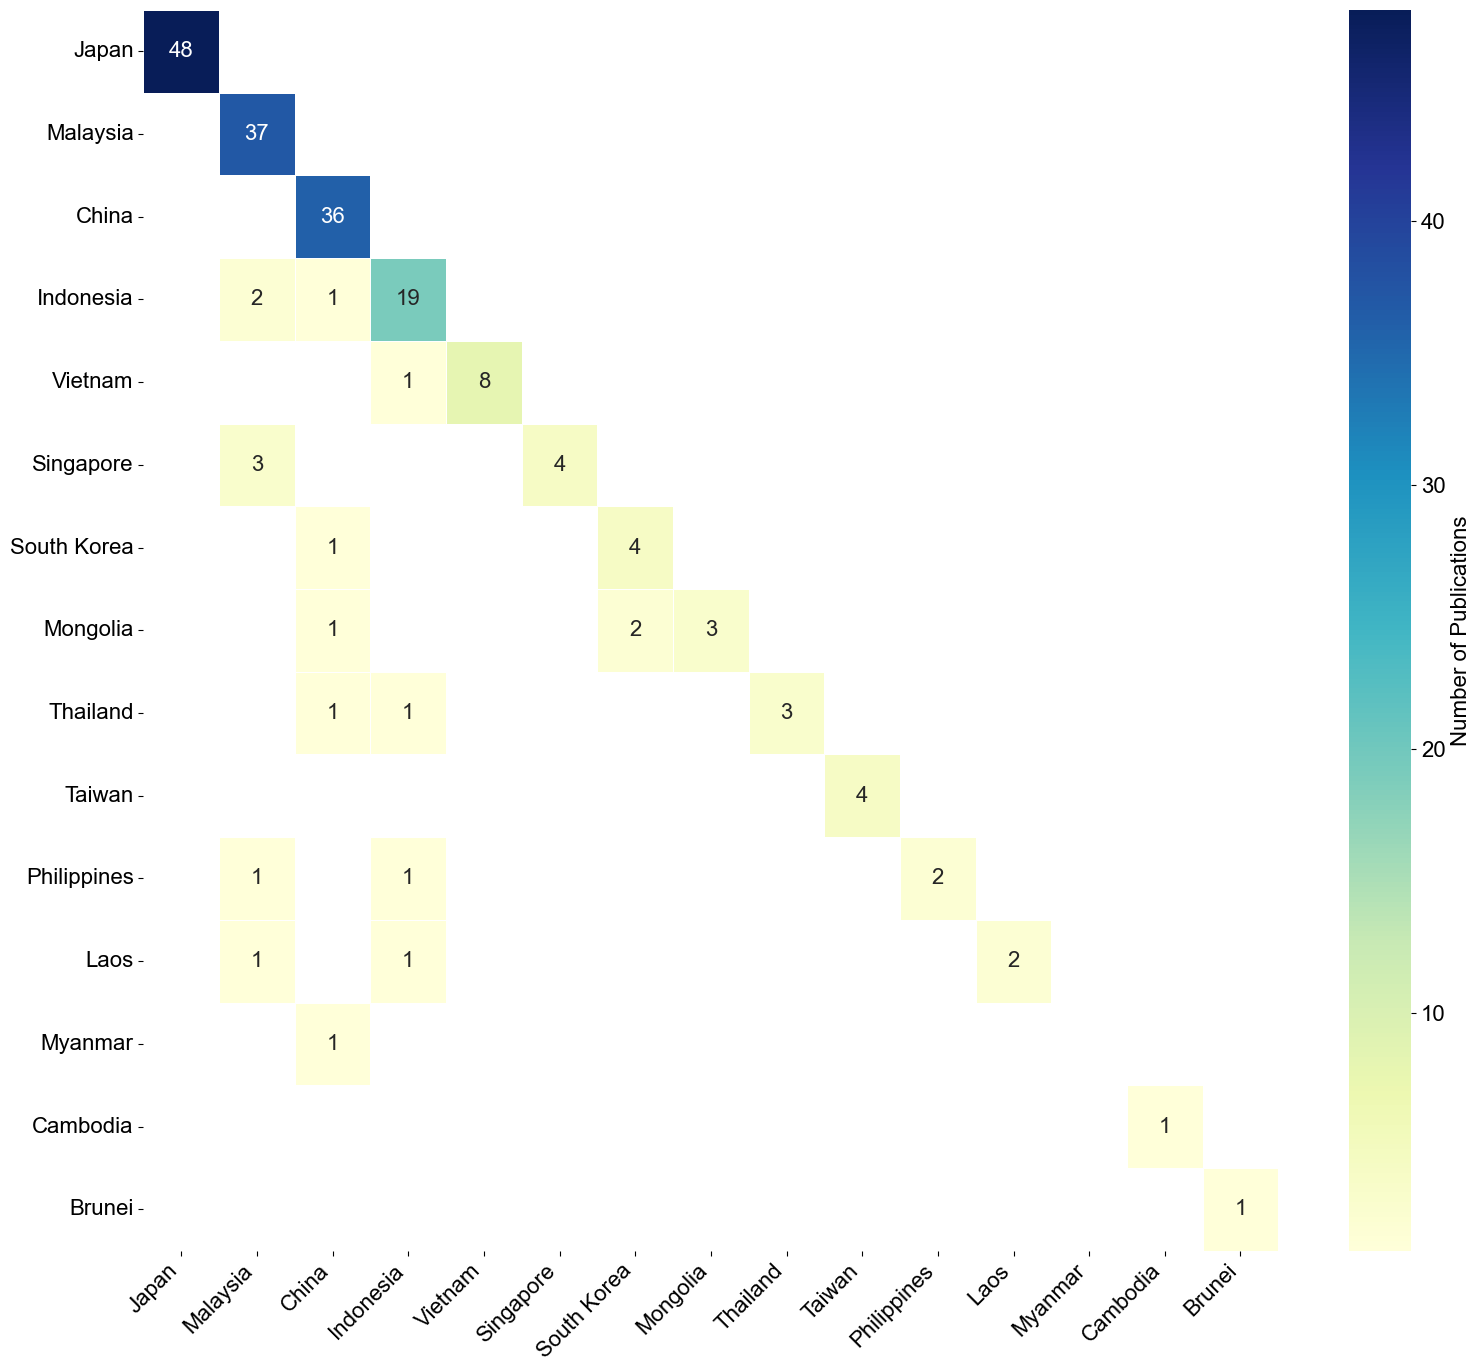

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'Arial' 

# Load the data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# Extract only country columns
country_cols = [col for col in df.columns if str(col).startswith('Country_')]
df_countries = df[country_cols].fillna(0)

# --- Sort countries by total publications ---
country_totals = df_countries.sum().sort_values(ascending=False)
sorted_countries = country_totals.index.tolist()
df_countries = df_countries[sorted_countries]

# Calculate co-occurrence matrix 
co_matrix = df_countries.T.dot(df_countries)

# Calculate single-country publications for the diagonal 
for col in df_countries.columns:
    single_count = len(df_countries[(df_countries[col] == 1) & (df_countries.sum(axis=1) == 1)])
    co_matrix.loc[col, col] = single_count

# Clean up column and index names 
co_matrix.index = [c.replace('Country_', '') for c in co_matrix.index]
co_matrix.columns = [c.replace('Country_', '') for c in co_matrix.columns]


upper_mask = np.triu(np.ones_like(co_matrix, dtype=bool), k=1)

mask = (co_matrix == 0) | upper_mask

# --- Create the heatmap ---
plt.figure(figsize=(16, 14)) 

sns.heatmap(co_matrix, cmap='YlGnBu', annot=True, fmt='g', 
            linewidths=.5, cbar_kws={'label': 'Number of Publications'},
            mask=mask) 

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.savefig('heatmap_lower_triangle.png', dpi=600)
plt.show()

Fig.1b

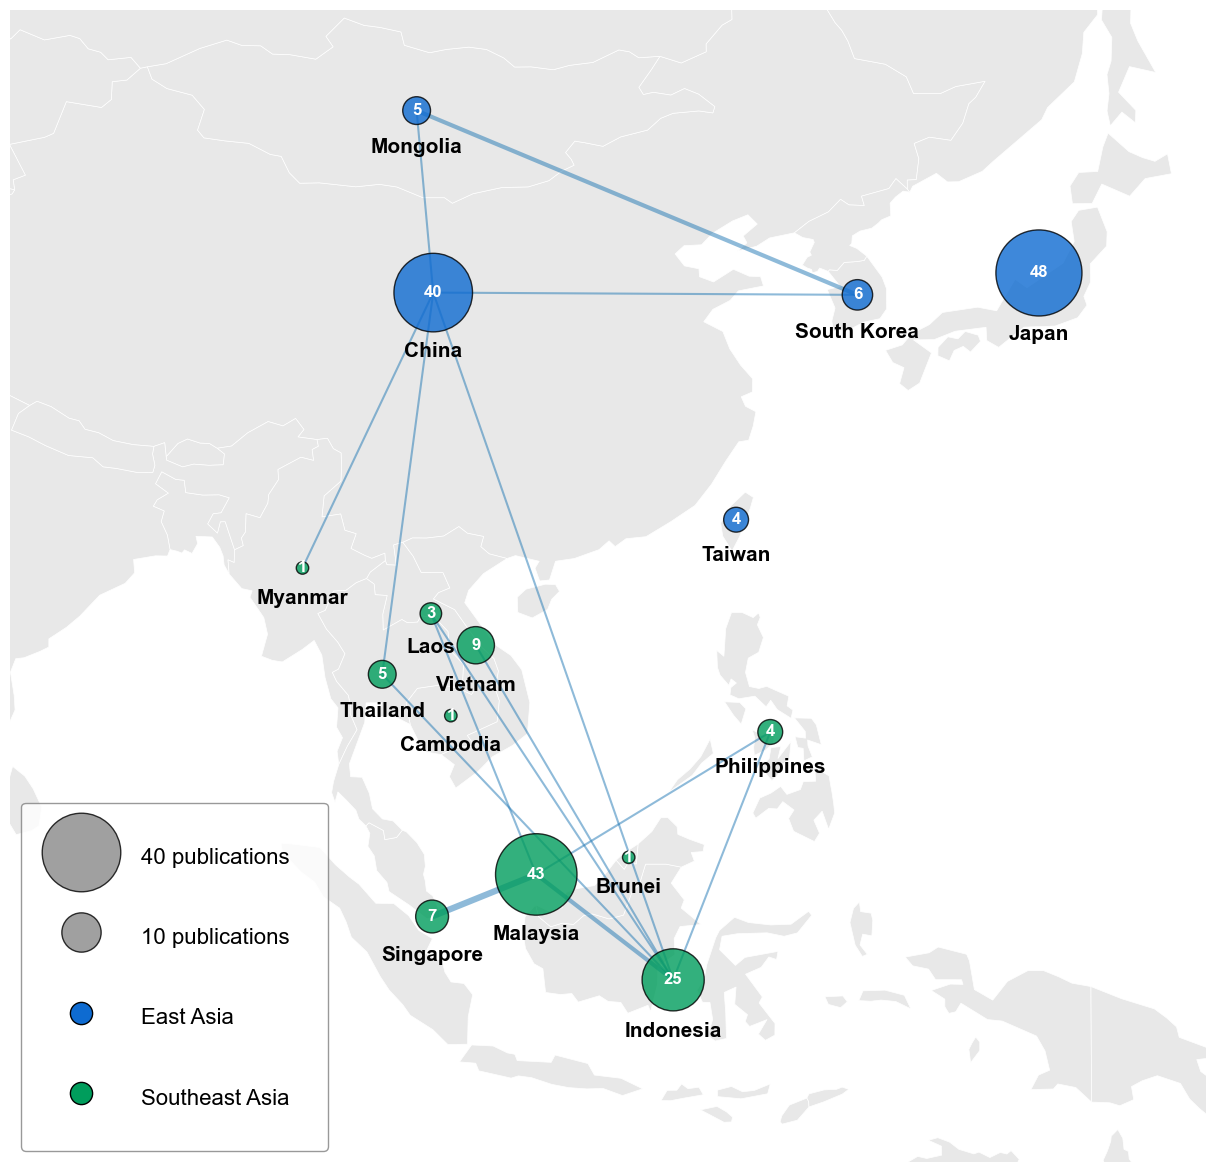

In [3]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import geopandas as gpd
from itertools import combinations
import warnings
import numpy as np
import matplotlib.lines as mlines

warnings.filterwarnings("ignore", category=UserWarning)

plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'Arial'

# ==========================================
# 1. Loading data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

country_cols = [col for col in df.columns if str(col).startswith('Country_')]
country_counts = df[country_cols].sum()
country_counts = country_counts[country_counts > 0]

edge_weights = {}
for index, row in df.iterrows():
    active_countries = [col.replace('Country_', '') for col in country_cols if row[col] == 1]
    if len(active_countries) >= 2:
        for pair in combinations(active_countries, 2):
            pair = tuple(sorted(pair))
            edge_weights[pair] = edge_weights.get(pair, 0) + 1

# ==========================================
# 2. Making Network
# ==========================================
G = nx.Graph()
for col, count in country_counts.items():
    country_name = col.replace('Country_', '')
    G.add_node(country_name, count=count)

for (country1, country2), weight in edge_weights.items():
    G.add_edge(country1, country2, weight=weight)

# ==========================================
# 3. GeoPandas
# ==========================================
url = "https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json"
world = gpd.read_file(url)

fallback_coords = {
    'Singapore': (103.8198, 1.3521),
    'Brunei': (114.7277, 4.5353),

    'Taiwan': (120.9605, 23.6978)
}

pos = {}
for country in G.nodes():
    match = world[world['name'] == country]
    if not match.empty:
        centroid = match.geometry.centroid.iloc[0]
        pos[country] = (centroid.x, centroid.y)
    elif country in fallback_coords:
        pos[country] = fallback_coords[country]
    else:
        pos[country] = (0, 0)

# ==========================================
# 4. Color mapping of node
# ==========================================
ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

node_colors = []
for node in G.nodes():
    if node in ea_countries:
        node_colors.append('#0E6BD1') 
    elif node in sea_countries:
        node_colors.append('#009D5C') 
    else:
        node_colors.append('#888888') 

# ==========================================
# 5. Illutrating network
# ==========================================
fig, ax = plt.subplots(figsize=(18, 12))

world.plot(ax=ax, color='#e8e8e8', edgecolor='white', linewidth=0.5)

NODE_SCALE = 80  
EDGE_SCALE = 1.5 

node_sizes = [G.nodes[n]['count'] * NODE_SCALE for n in G.nodes()]
edge_widths = [G.edges[u, v]['weight'] * EDGE_SCALE for u, v in G.edges()]


legend_values = [40, 10] 
legend_handles = []

for val in legend_values:
    size_in_points = np.sqrt(val * NODE_SCALE) 
    handle = mlines.Line2D([], [], color='white', marker='o', markerfacecolor='#888888',
                           markeredgecolor='black', markersize=size_in_points, 
                           label=f'{val} publications', alpha=0.8)
    legend_handles.append(handle)

ea_handle = mlines.Line2D([], [], color='white', marker='o', markerfacecolor='#0E6BD1', markeredgecolor='black', markersize=16, label='East Asia')
sea_handle = mlines.Line2D([], [], color='white', marker='o', markerfacecolor='#009D5C', markeredgecolor='black', markersize=16, label='Southeast Asia')
legend_handles.extend([ea_handle, sea_handle])

ax.legend(handles=legend_handles, 
          loc="lower left", 
          fontsize=16, frameon=True, facecolor='white', edgecolor='gray',
          labelspacing=2.2,      
          borderpad=1.7,         
          handletextpad=1.7,     
          handleheight=1.8)      


nx.draw_networkx_edges(G, pos, ax=ax, width=edge_widths, alpha=0.5, edge_color='#1f77b4')
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes, 
                       node_color=node_colors, alpha=0.8, edgecolors='black', linewidths=1)


label_pos_names = {}
for k, v in pos.items():
    count = G.nodes[k]['count']
    offset = 1.4 + np.sqrt(count) * 0.3
    label_pos_names[k] = (v[0], v[1] - offset)

nx.draw_networkx_labels(G, label_pos_names, ax=ax, font_size=15, font_weight='bold', font_family='Arial')


number_labels = {n: str(G.nodes[n]['count']) for n in G.nodes()}
nx.draw_networkx_labels(G, pos, labels=number_labels, ax=ax, 
                        font_size=12, font_color='white', font_weight='bold', font_family='Arial',
                        verticalalignment='center', horizontalalignment='center')


ax.set_xlim([80, 147.5]) 
ax.set_ylim([-12.5, 52.5])

plt.axis('off') 
plt.tight_layout()
plt.savefig('map_collaboration_network_clean.png', dpi=600)
plt.show()

FIg.2a

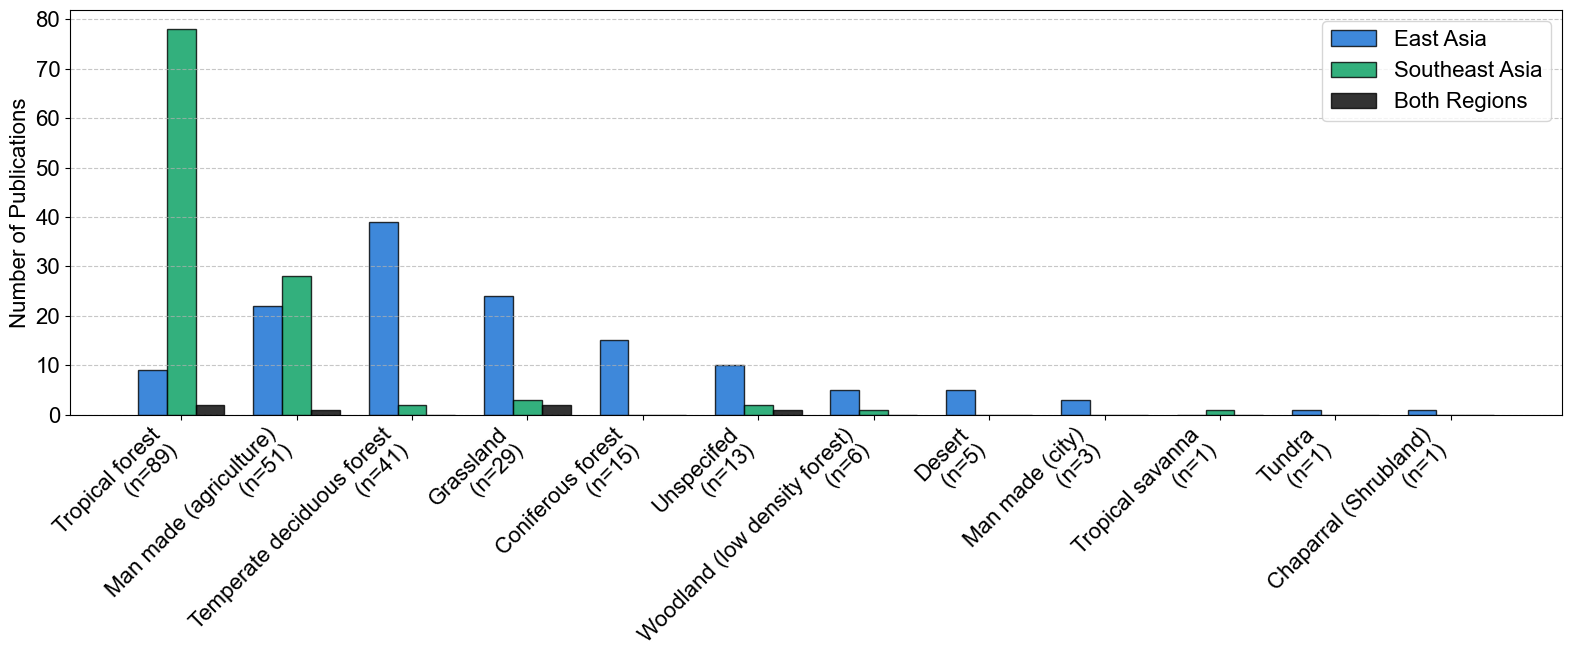

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 16


# ==========================================
# 1. Load data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# ==========================================
# 2. Extract Habitats and Determine Order
# ==========================================
habitat_cols = [col for col in df.columns if str(col).startswith('Habitat_')]

# Calculate the total sum for each habitat to determine the correct order
habitat_counts = df[habitat_cols].sum().sort_values(ascending=False)
habitat_counts = habitat_counts[habitat_counts > 0]
ordered_habitats = habitat_counts.index.tolist()

# Clean up labels (remove 'Habitat_' prefix)
habitat_labels = [f"{label.replace('Habitat_', '')}\n (n={int(habitat_counts[label])})" for label in ordered_habitats]


# ==========================================
# 3. Determine Region Labels for each paper
# ==========================================
def get_region_label(row):
    ea = row.get('Region_East Asia', 0)
    sea = row.get('Region_Southeast Asia', 0)
    if ea == 1 and sea == 1:
        return 'Both'
    elif ea == 1 and sea == 0:
        return 'East Asia'
    elif ea == 0 and sea == 1:
        return 'Southeast Asia'
    else:
        return 'Other'

df['Region_Label'] = df.apply(get_region_label, axis=1)

# ==========================================
# 4. Prepare data for grouped bar chart
# ==========================================
ea_counts = []
sea_counts = []
both_counts = []

for hab in ordered_habitats:
    # Get all papers for the specific habitat
    subset = df[df[hab] == 1]
    
    # Count how many belong to each region
    counts = subset['Region_Label'].value_counts()
    
    ea_counts.append(counts.get('East Asia', 0))
    sea_counts.append(counts.get('Southeast Asia', 0))
    both_counts.append(counts.get('Both', 0))

# Convert to numpy arrays
ea_counts = np.array(ea_counts)
sea_counts = np.array(sea_counts)
both_counts = np.array(both_counts)

# ==========================================
# 5. Plotting (Grouped Bar Chart)
# ==========================================
plt.rcParams['font.family'] = 'Arial' 
fig, ax = plt.subplots(figsize=(16, 7))

# Set position of bar on X axis
x = np.arange(len(habitat_labels)) 
width = 0.25  # Width of each individual bar

# Plot each region's bars side-by-side
ax.bar(x - width, ea_counts, width, label='East Asia', color='#0E6BD1', edgecolor='black', alpha=0.8)
ax.bar(x, sea_counts, width, label='Southeast Asia', color='#009D5C', edgecolor='black', alpha=0.8)
ax.bar(x + width, both_counts, width, label='Both Regions', color='black', edgecolor='black', alpha=0.8)

# Add labels
# ax.set_xlabel('Habitat', fontsize=12)
ax.set_ylabel('Number of Publications', fontsize=16)

# Set X-axis ticks to center on the middle bar
ax.set_xticks(x)
ax.set_xticklabels(habitat_labels, rotation=45, ha='right', fontsize=16)

# Add Legend
ax.legend(fontsize=16)

# Add grid
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('habitat_grouped_counts.png', dpi=600)
plt.show()

Fig.S4

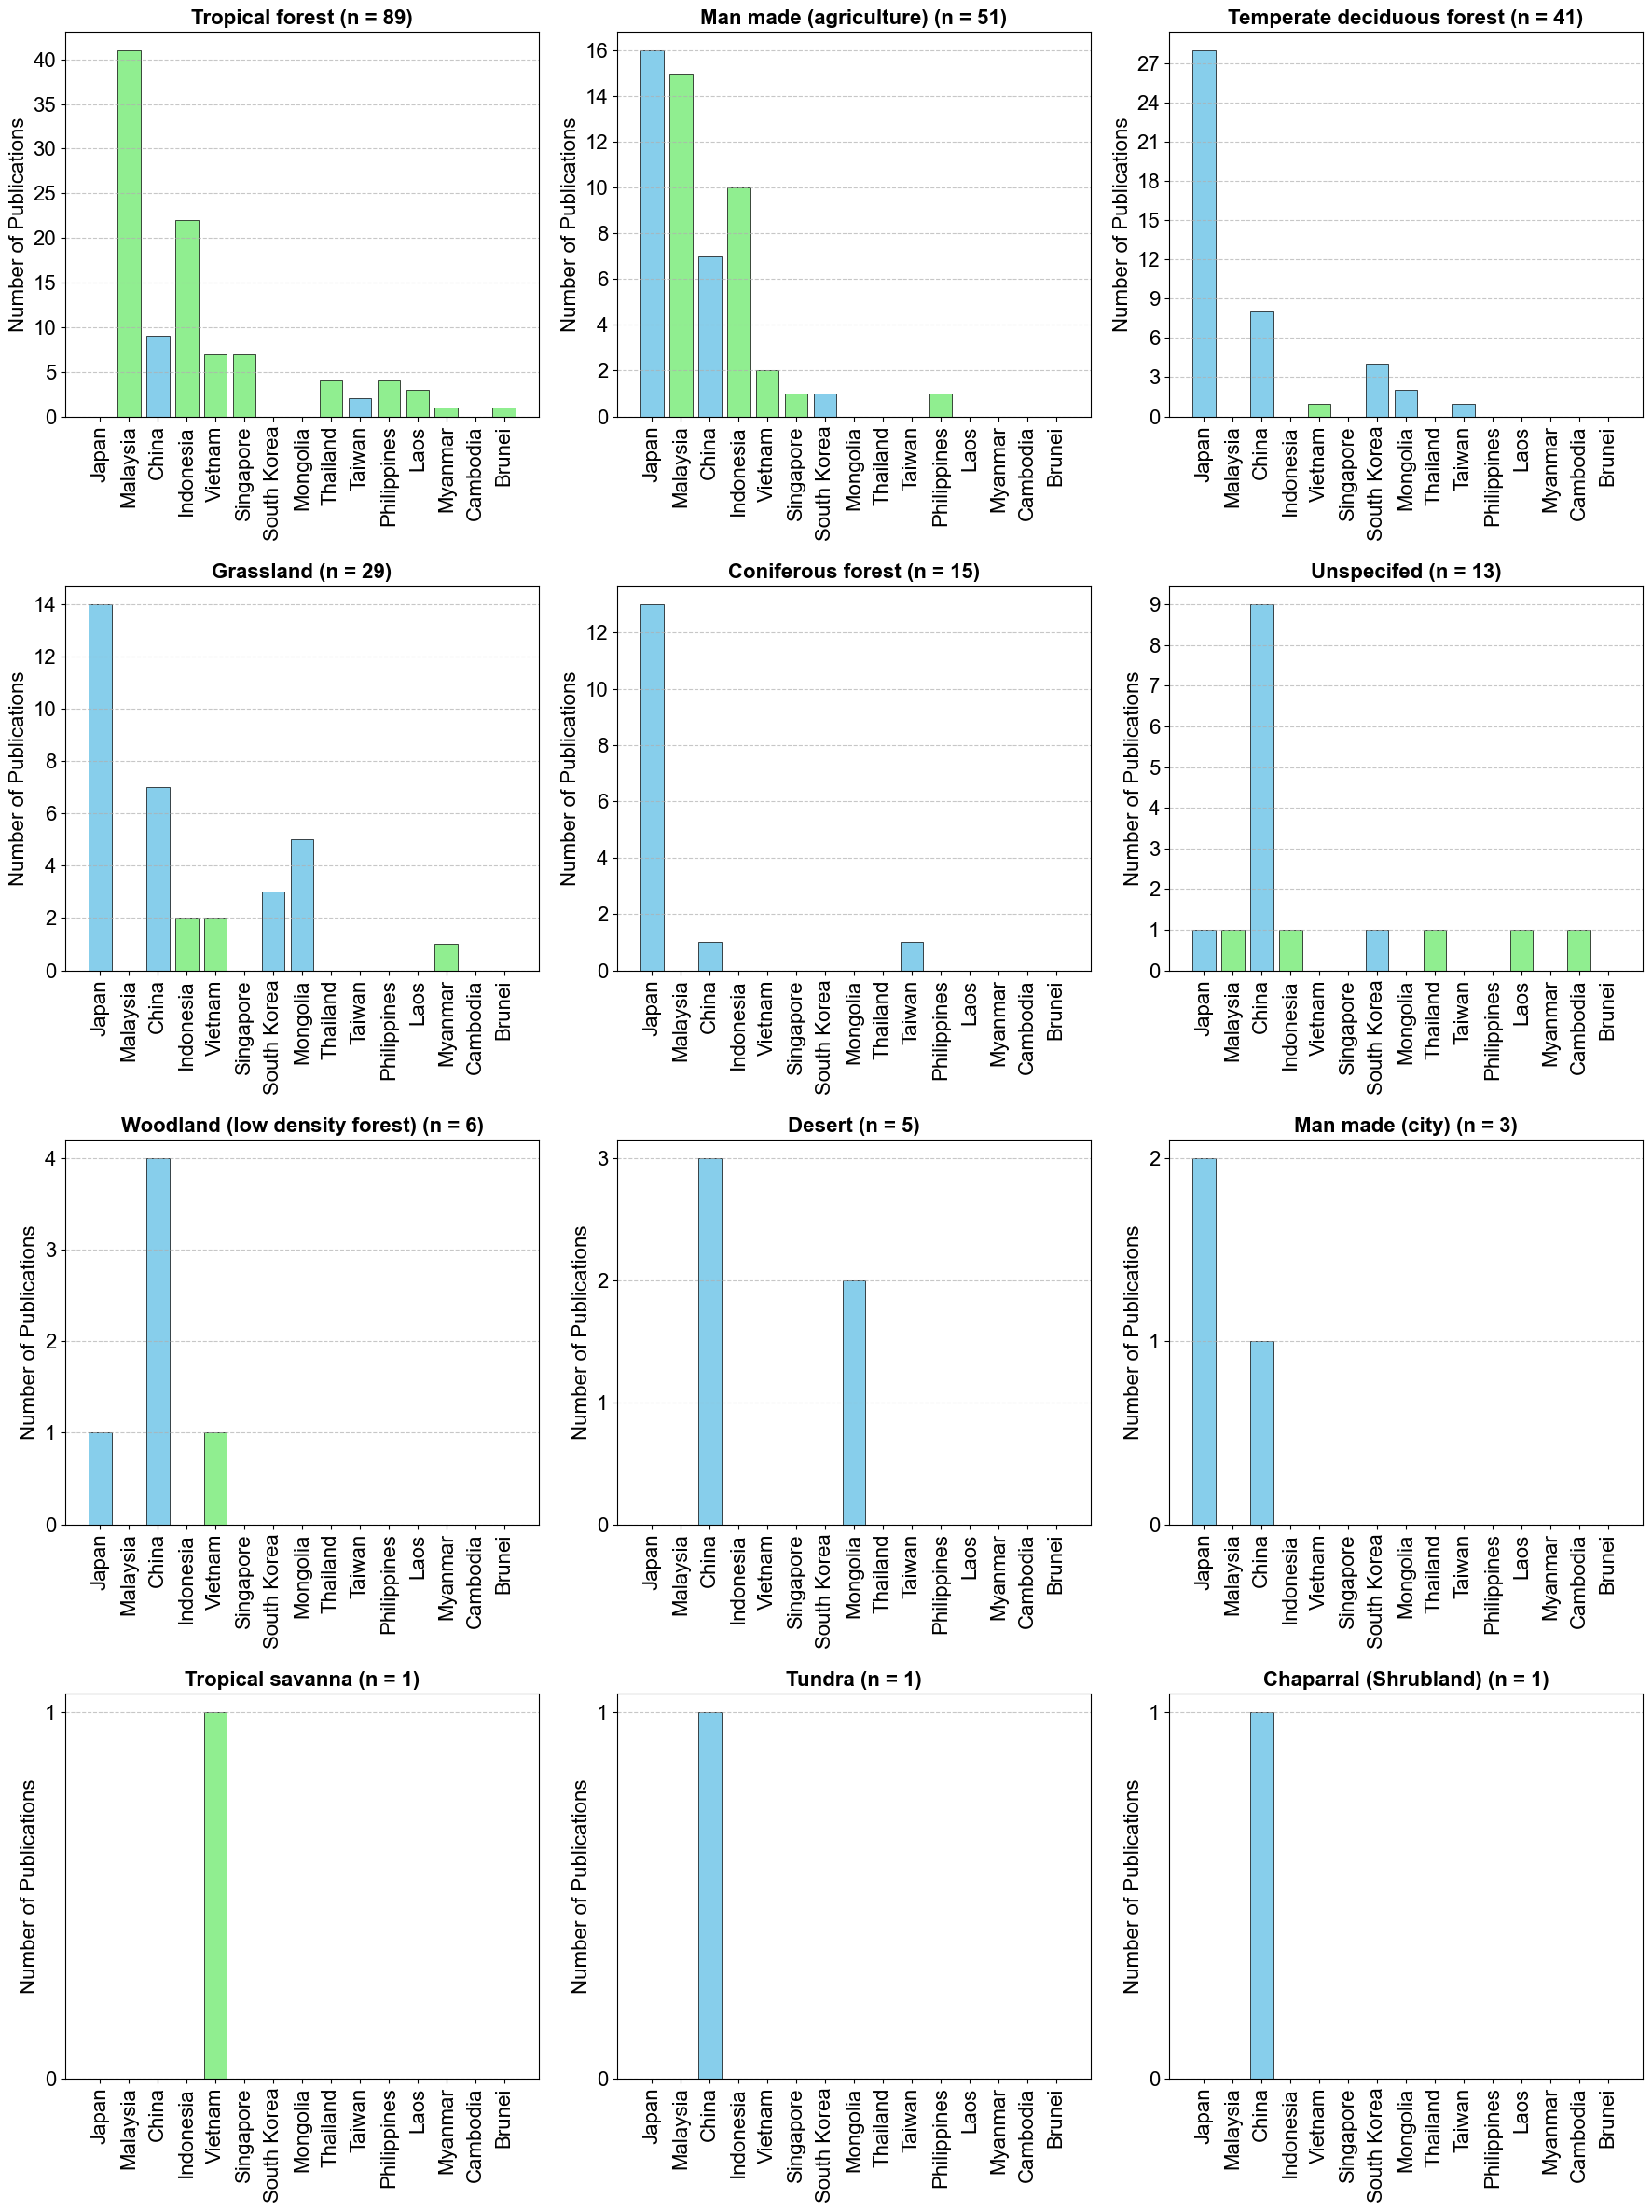

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 16

# 1. Load data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# --- Habitat Data Prep ---
# Extract columns starting with 'Habitat_'
habitat_cols = [col for col in df.columns if str(col).startswith('Habitat_')]
habitat_totals = {}
for col in habitat_cols:
    subset = df[df[col] == 1]
    if len(subset) > 0:
        habitat_totals[col] = len(subset)

# Sort habitats by total publications descending
sorted_habitats = sorted(habitat_totals.items(), key=lambda x: x[1], reverse=True)

# --- X-axis elements setup (Countries Only) ---
country_cols = [col for col in df.columns if str(col).startswith('Country_')]
country_totals = {col: df[col].sum() for col in country_cols}
sorted_countries = [col for col, val in sorted(country_totals.items(), key=lambda x: x[1], reverse=True) if val > 0]

ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

x_labels = []
x_cols = []
colors = []

# Add countries only
for col in sorted_countries:
    c_name = col.replace('Country_', '')
    x_labels.append(c_name)
    x_cols.append(col)
    
    # Assign specific colors based on region
    if c_name in ea_countries:
        colors.append('skyblue')
    elif c_name in sea_countries:
        colors.append('lightgreen')
    else:
        colors.append('lightgray')

# --- Create Subplots ---
n_habitats = len(sorted_habitats)
cols_per_row = 3
n_rows = math.ceil(n_habitats / cols_per_row)

fig, axes = plt.subplots(n_rows, cols_per_row, figsize=(18, 6 * n_rows))

# Prevent indexing error if there is only one subplot
if n_habitats == 1:
    axes = np.array([axes])
axes = axes.flatten()

for i, (habitat_col, total_count) in enumerate(sorted_habitats):
    ax = axes[i]
    habitat_name = habitat_col.replace('Habitat_', '')
    
    subset = df[df[habitat_col] == 1]
    
    y_values = []
    for x_col in x_cols:
        y_values.append(subset[x_col].sum())
            
    x_pos = range(len(x_labels))
    ax.bar(x_pos, y_values, color=colors, edgecolor='black', linewidth=0.5)
    
    ax.set_title(f'{habitat_name} (n = {total_count})', fontsize=16, fontweight='bold')
    ax.set_ylabel('Number of Publications', fontsize=16)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=16)
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # --- CHANGED: Added padding to left and right bounds ---
    # Original: ax.set_xlim(-0.5, len(x_labels) - 0.5)
    ax.set_xlim(-1.2, len(x_labels) + 0.2)

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('habitat_country_subplots.png', dpi=600)
plt.show()

Fig.2b

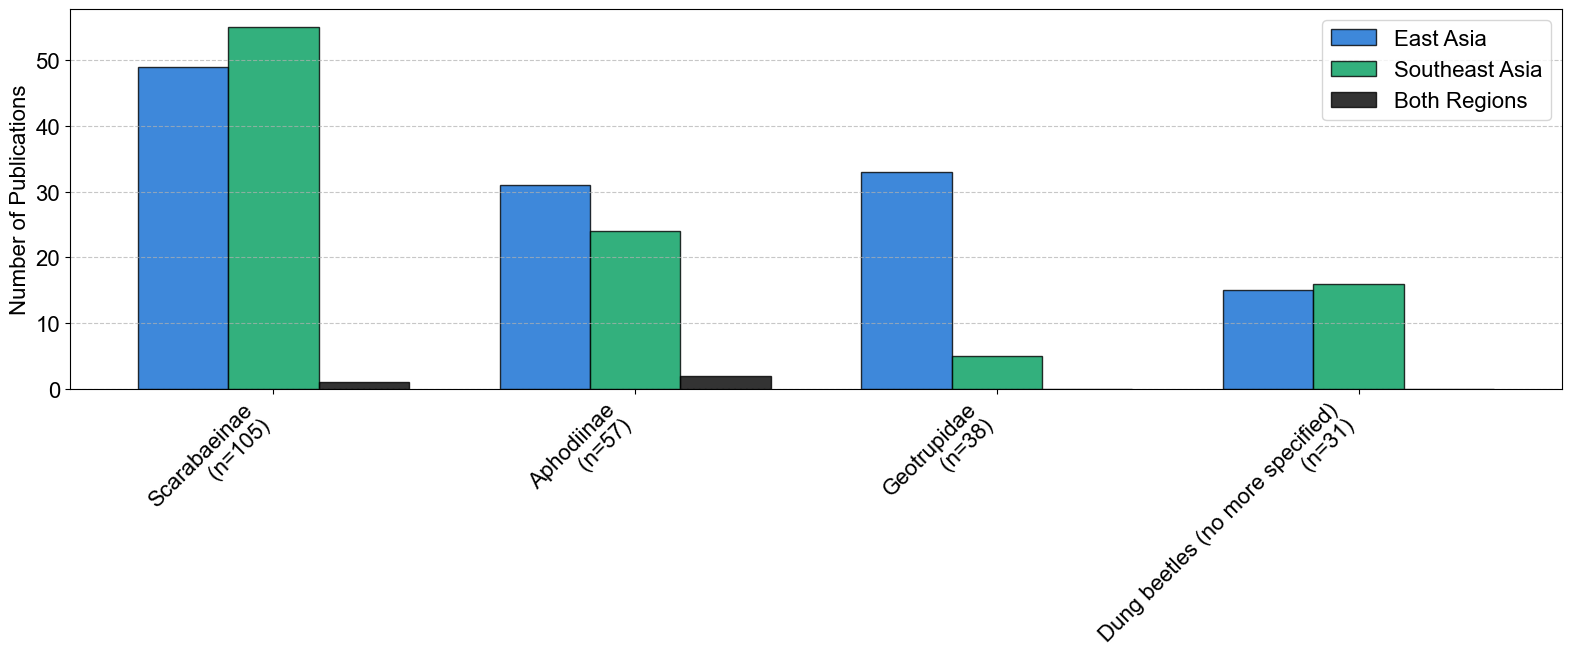

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'Arial'

# ==========================================
# 1. Load Data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)



# ==========================================
# 2. Extract Taxa and Determine Order
# ==========================================
taxon_cols = [
    col for col in df.columns 
    if str(col).startswith('Taxon_') and 'Other (specify)' not in str(col)
]

# Calculate total publications for each taxon to determine the correct order
taxon_counts = df[taxon_cols].sum().sort_values(ascending=False)
taxon_counts = taxon_counts[taxon_counts > 0]
ordered_taxa = taxon_counts.index.tolist()

# 名前の後に改行(\n)と(n=総数)を追加する
taxon_labels = [f"{label.replace('Taxon_', '')}\n (n={int(taxon_counts[label])})" for label in ordered_taxa]

# ==========================================
# 3. Determine Region Labels for each paper
# ==========================================
def get_region_label(row):
    ea = row.get('Region_East Asia', 0)
    sea = row.get('Region_Southeast Asia', 0)
    if ea == 1 and sea == 1:
        return 'Both'
    elif ea == 1 and sea == 0:
        return 'East Asia'
    elif ea == 0 and sea == 1:
        return 'Southeast Asia'
    else:
        return 'Other'

df['Region_Label'] = df.apply(get_region_label, axis=1)

# ==========================================
# 4. Prepare data for grouped bar chart
# ==========================================
ea_counts = []
sea_counts = []
both_counts = []

for taxon in ordered_taxa:
    subset = df[df[taxon] == 1]
    counts = subset['Region_Label'].value_counts()
    
    ea_counts.append(counts.get('East Asia', 0))
    sea_counts.append(counts.get('Southeast Asia', 0))
    both_counts.append(counts.get('Both', 0))

ea_counts = np.array(ea_counts)
sea_counts = np.array(sea_counts)
both_counts = np.array(both_counts)

# ==========================================
# 5. Plotting (Grouped Bar Chart)
# ==========================================
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(16, 7))

# Set position of bar on X axis
x = np.arange(len(taxon_labels)) 
width = 0.25  # Width of each individual bar

# Plot each region's bars side-by-side
ax.bar(x - width, ea_counts, width, label='East Asia', color='#0E6BD1', edgecolor='black', alpha=0.8)
ax.bar(x, sea_counts, width, label='Southeast Asia', color='#009D5C', edgecolor='black', alpha=0.8)
ax.bar(x + width, both_counts, width, label='Both Regions', color='black', edgecolor='black', alpha=0.8)

# Add labels
ax.set_ylabel('Number of Publications', fontsize=16)

# Set X-axis ticks to center on the middle bar
ax.set_xticks(x)
ax.set_xticklabels(taxon_labels, rotation=45, ha='right', fontsize=16)

# Add Legend
ax.legend(fontsize=16)

# Add grid
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('taxon_grouped_counts_no_other.png', dpi=600)
plt.show()

Fig.S5

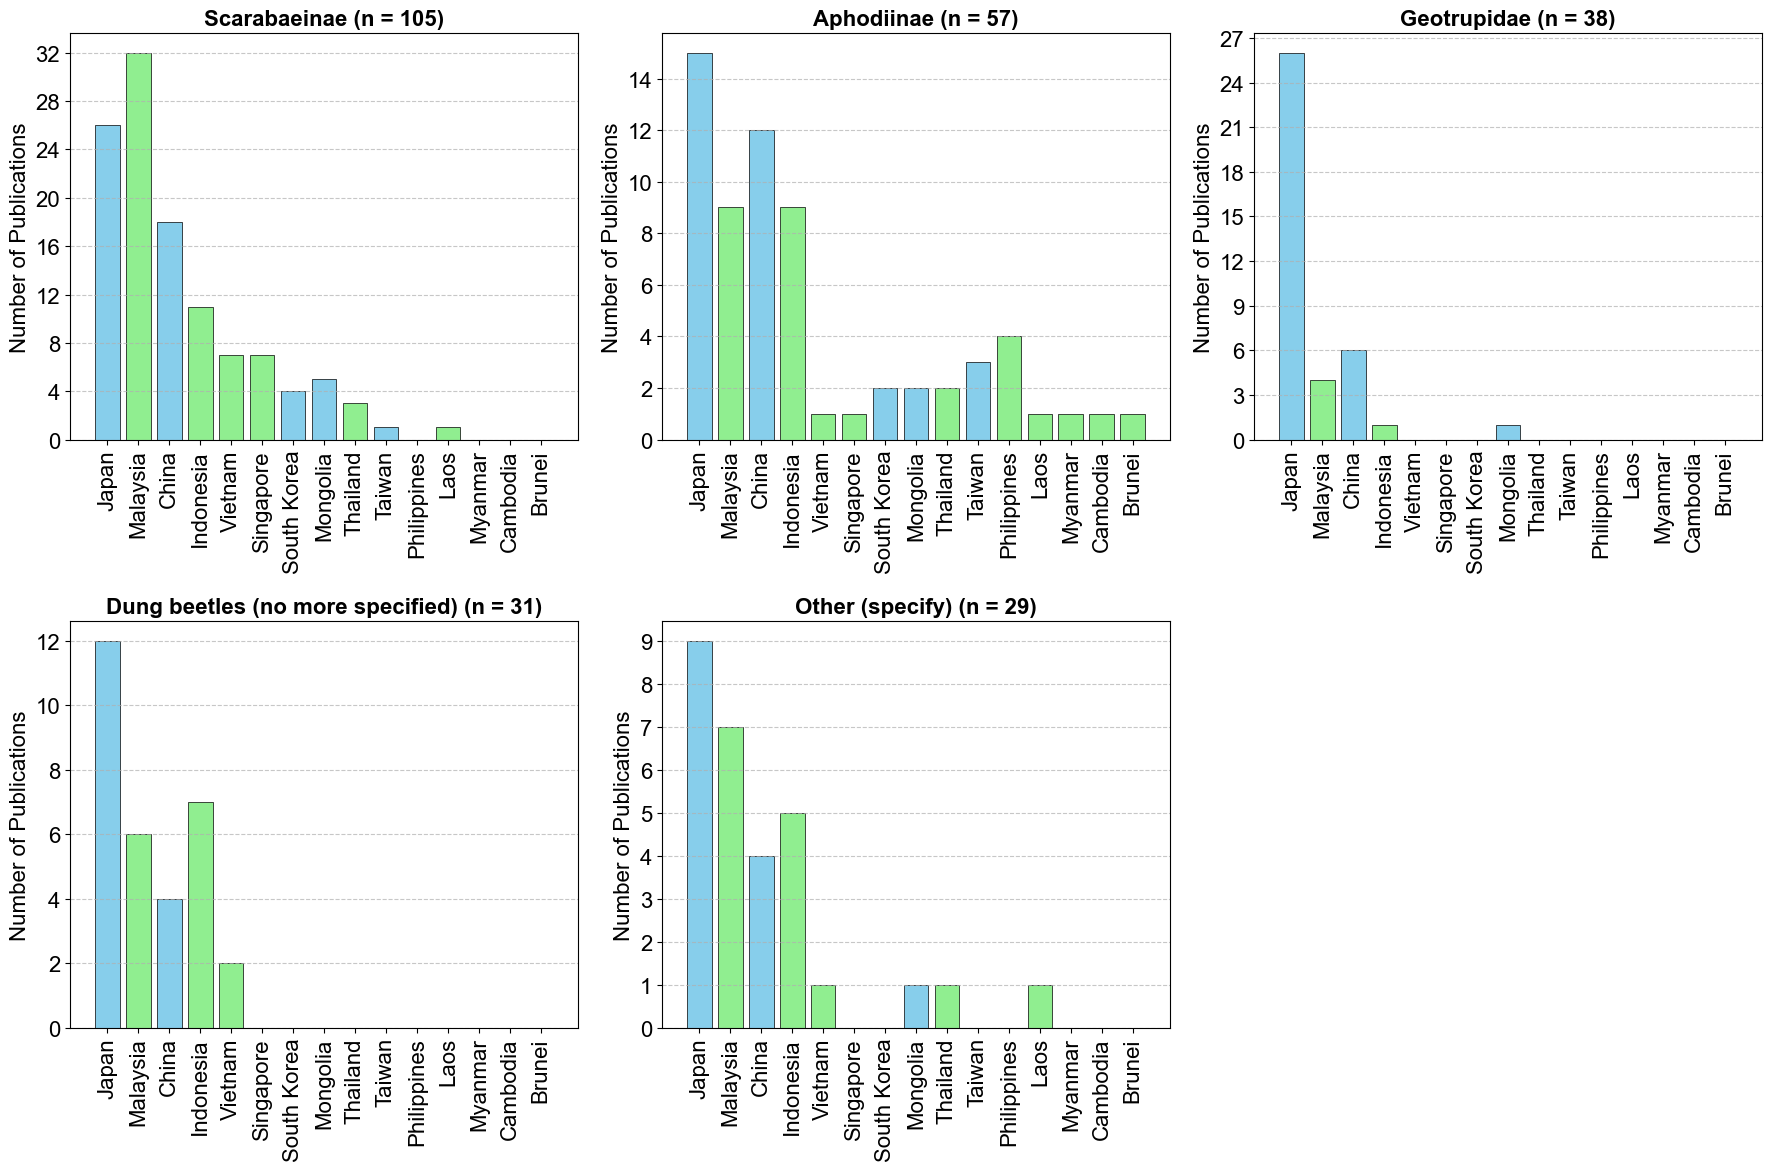

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 16

# ==========================================
# 1. Load Data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# ==========================================
# 2. Data Preparation for Taxon Overall Totals
# ==========================================
# Extract columns starting with 'Taxon_'
taxon_cols = [col for col in df.columns if str(col).startswith('Taxon_')]

# Calculate total publications for each taxon and sort descending
taxon_totals = df[taxon_cols].sum().sort_values(ascending=False)
taxon_totals = taxon_totals[taxon_totals > 0] # Filter out taxa with 0 counts

# ==========================================
# 3. Data Preparation for Country X-axis (Regions removed)
# ==========================================
# Extract country columns and calculate their overall totals for sorting
country_cols = [col for col in df.columns if str(col).startswith('Country_')]
country_totals_dict = {col: df[col].sum() for col in country_cols}

# Sort countries by total publication count in descending order
sorted_countries = [col for col, val in sorted(country_totals_dict.items(), key=lambda x: x[1], reverse=True) if val > 0]

# Define regions for color mapping
ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

x_labels = []
x_cols = []
bar_colors = []

# Add Countries to X-axis
for col in sorted_countries:
    c_name = col.replace('Country_', '')
    x_labels.append(c_name)
    x_cols.append(col)
    
    # Assign specific colors based on region
    if c_name in ea_countries:
        bar_colors.append('skyblue')
    elif c_name in sea_countries:
        bar_colors.append('lightgreen')
    else:
        bar_colors.append('lightgray')

# ==========================================
# 4. Plot: Subplots by Taxon (Countries Only)
# ==========================================
n_taxa = len(taxon_totals)
cols_per_row = 3
n_rows = math.ceil(n_taxa / cols_per_row)

# Create figure and axes
fig, axes = plt.subplots(n_rows, cols_per_row, figsize=(18, 6 * n_rows))

# Handle cases where there might be only 1 row or 1 plot
if n_taxa == 1:
    axes = np.array([axes])
axes = axes.flatten()

# Iterate over each taxon to create a subplot
for i, (taxon_col, total_count) in enumerate(taxon_totals.items()):
    ax = axes[i]
    
    # Clean up taxon name for the subplot title
    taxon_name = taxon_col.replace('Taxon_', '')
    
    # Subset dataframe where this specific taxon is present
    subset = df[df[taxon_col] == 1]
    
    y_values = []
    for x_col in x_cols:
        y_values.append(subset[x_col].sum())
            
    x_pos = range(len(x_labels))
    
    # Draw bar chart using consistent region/country colors
    ax.bar(x_pos, y_values, color=bar_colors, edgecolor='black', linewidth=0.5)
    
    # Set titles and labels
    ax.set_title(f'{taxon_name} (n = {int(total_count)})', fontsize=16, fontweight='bold')
    ax.set_ylabel('Number of Publications', fontsize=16)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=16)
    
    # Force Y-axis ticks to be integers only
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Added padding to left and right bounds
    ax.set_xlim(-1.2, len(x_labels) + 0.2)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('taxon_fields_subplots.png', dpi=600)
plt.show()

Fig. S6

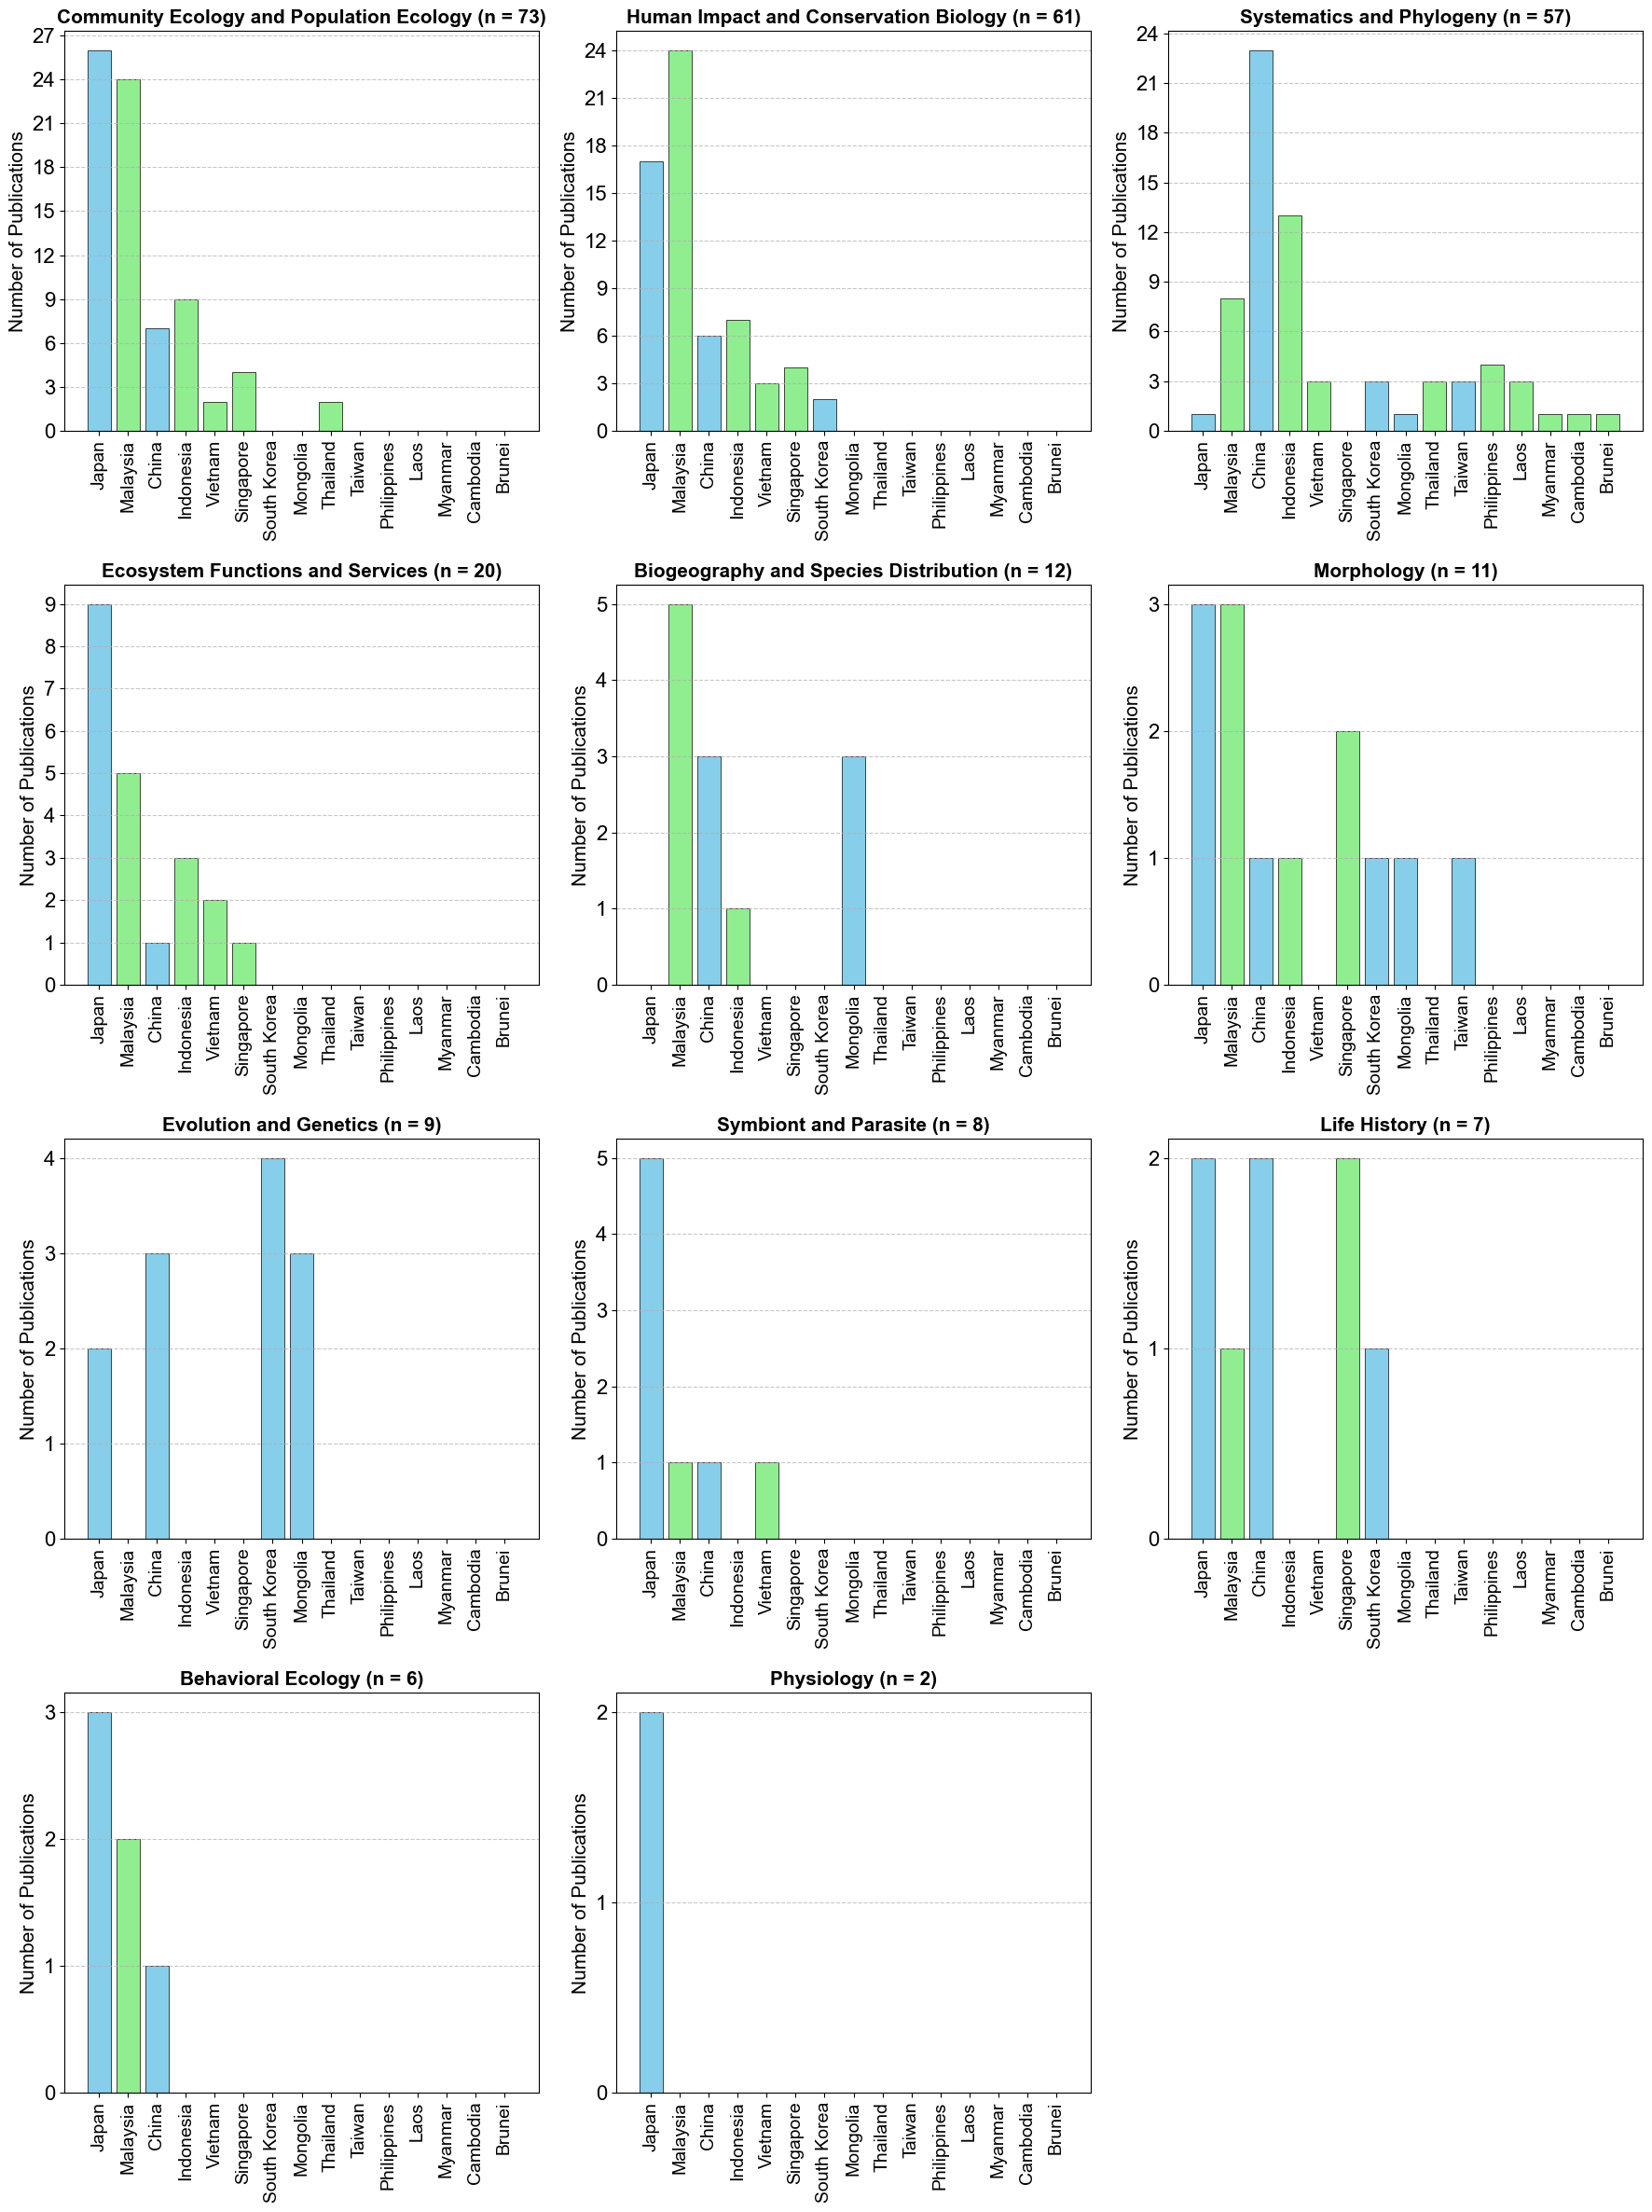

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'Arial'


# 1. Load data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# --- 1. Topics Data Prep ---
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]
topic_totals = {}
for col in topic_cols:
    subset = df[df[col] == 1]
    if len(subset) > 0:
        topic_totals[col] = len(subset)

# Sort topics by total publications descending
sorted_topics = sorted(topic_totals.items(), key=lambda x: x[1], reverse=True)

# --- 2. X-axis elements setup (Countries Only) ---
country_cols = [col for col in df.columns if str(col).startswith('Country_')]
country_totals = {col: df[col].sum() for col in country_cols}
sorted_countries = [col for col, val in sorted(country_totals.items(), key=lambda x: x[1], reverse=True) if val > 0]

ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

x_labels = []
x_cols = []
colors = []

# Add countries only
for col in sorted_countries:
    c_name = col.replace('Country_', '')
    x_labels.append(c_name)
    x_cols.append(col)
    
    # Assign specific colors based on region
    if c_name in ea_countries:
        colors.append('skyblue')
    elif c_name in sea_countries:
        colors.append('lightgreen')
    else:
        colors.append('lightgray')

# --- 3. Create Subplots ---
n_topics = len(sorted_topics)
cols_per_row = 3 
n_rows = math.ceil(n_topics / cols_per_row)

fig, axes = plt.subplots(n_rows, cols_per_row, figsize=(18, 6 * n_rows))

# Prevent indexing error if there is only one subplot
if n_topics == 1:
    axes = np.array([axes])
axes = axes.flatten()

for i, (topic_col, total_count) in enumerate(sorted_topics):
    ax = axes[i]
    topic_name = topic_col.replace('Research topic_', '')
    subset = df[df[topic_col] == 1]
    
    y_values = []
    for x_col in x_cols:
        y_values.append(subset[x_col].sum())
            
    x_pos = range(len(x_labels))
    ax.bar(x_pos, y_values, color=colors, edgecolor='black', linewidth=0.5)
    
    ax.set_title(f'{topic_name} (n = {total_count})', fontsize=15, fontweight='bold')
    ax.set_ylabel('Number of Publications', fontsize=15)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=14)
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Added padding to left and right bounds (Matches previous habitat chart)
    ax.set_xlim(-1.2, len(x_labels) + 0.2)

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('topic_country_subplots.png', dpi=600)
plt.show()

Fig.S7

C:\Users\r-aka\AppData\Local\Temp\ipykernel_4672\2426176454.py:71: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab20', len(topics))


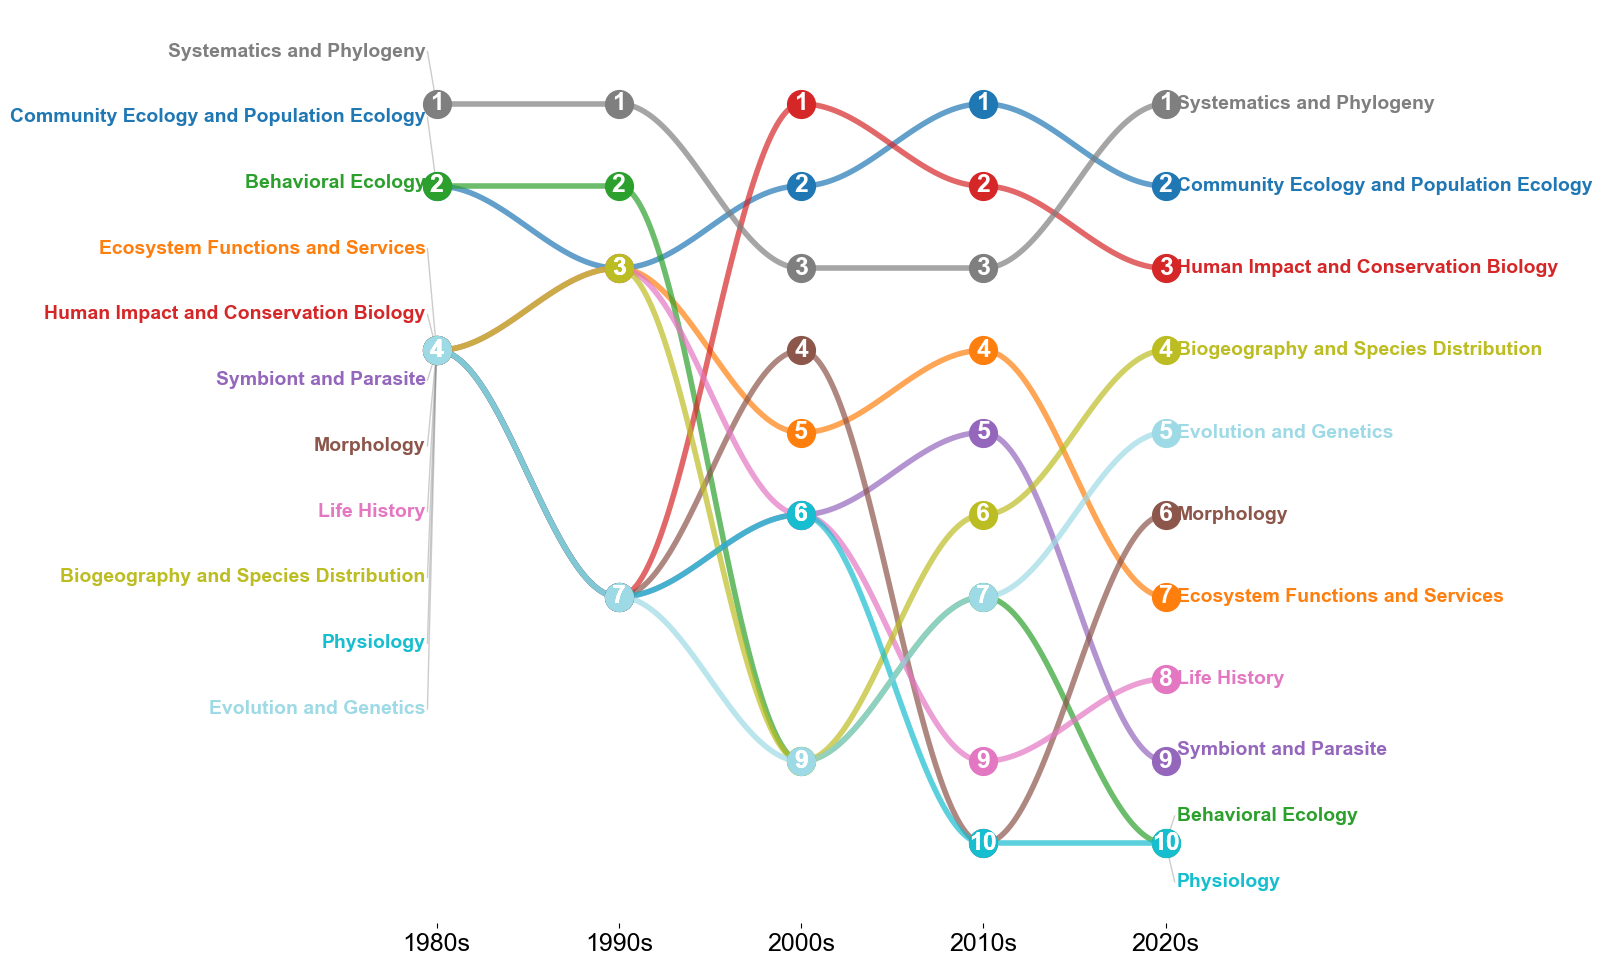

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 18

# ==========================================
# 1. Load Data 
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

# Filter data: 1980 onwards 
df = df[(df['Publication Year'] >= 1980)].copy()

# List of old/duplicate columns to exclude 
cols_to_drop = [
    'Research topic_Community Ecology',
    'Research topic_Population Ecology',
    'Research topic_Human Impact',
    'Research topic_Conservation Biology'
]

# Get topic columns, excluding old ones 
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_') and col not in cols_to_drop]

# Calculate the start year of 10-year periods (decades) 
df['Start_Year'] = (df['Publication Year'] // 10) * 10

# Calculate the total number of each topic per decade 
df_period = df.groupby('Start_Year')[topic_cols].sum()
# Clean up column names 
df_period.columns = [col.replace('Research topic_', '') for col in df_period.columns]

# Rank topics by publication count in descending order 
df_rank = df_period.rank(axis=1, method='min', ascending=False)

# ==========================================
# 2. Helper Functions 
# ==========================================
# Function to draw a smooth S-curve 
def draw_smooth_line(ax, x0, y0, x1, y1, color, lw=4):
    x_val = np.linspace(x0, x1, 100)
    t = (x_val - x0) / (x1 - x0) # Normalize 
    y_val = y0 + (y1 - y0) * (1 - np.cos(t * np.pi)) / 2
    ax.plot(x_val, y_val, color=color, linewidth=lw, alpha=0.7)

# Function to force a minimum vertical distance between labels 
def get_spaced_y_positions(ranks_series, min_dist=0.6):
    sorted_items = sorted(ranks_series.items(), key=lambda item: item[1])
    topics = [item[0] for item in sorted_items]
    ys = [item[1] for item in sorted_items]

    # Iteratively push overlapping labels apart 
    for _ in range(200): 
        for i in range(len(ys) - 1):
            if ys[i+1] - ys[i] < min_dist:
                diff = min_dist - (ys[i+1] - ys[i])
                ys[i] -= diff / 2
                ys[i+1] += diff / 2
    return dict(zip(topics, ys))

# ==========================================
# 3. Plotting 
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))

years = df_rank.index.tolist()
topics = df_rank.columns.tolist()
colors = plt.cm.get_cmap('tab20', len(topics))

# Calculate spaced Y positions 
left_y_pos = get_spaced_y_positions(df_rank.loc[years[0]], min_dist=0.8)
right_y_pos = get_spaced_y_positions(df_rank.loc[years[-1]], min_dist=0.8)

left_y_offset = 1

label_fontsize = 14

for i, topic in enumerate(topics):
    col_color = colors(i)
    ranks = df_rank[topic].values
    
    # Draw smooth lines 
    for j in range(len(years) - 1):
        draw_smooth_line(ax, years[j], ranks[j], years[j+1], ranks[j+1], col_color)
    
    # Draw points (circles) 
    ax.scatter(years, ranks, color=col_color, s=400, zorder=5)
    
    # Add rank numbers inside the points 
    for j, year in enumerate(years):
        ax.text(year, ranks[j], str(int(ranks[j])), color='white', 
                ha='center', va='center', fontweight='bold', zorder=6)
        
    # --- Add labels with Leader Lines---
    
    # Left side (1980s) 
    target_y_left = left_y_pos[topic] + left_y_offset
    
    # Draw leader line 
    ax.plot([years[0], years[0] - 0.5], [ranks[0], target_y_left], color='grey', alpha=0.4, linewidth=1, zorder=1)
    
    # Draw text 
    ax.text(years[0] - 0.6, target_y_left, topic, ha='right', va='center', 
            fontsize=label_fontsize, fontweight='bold', color=col_color) 

    # Right side (Most recent) 
    target_y_right = right_y_pos[topic]
    
    # Draw leader line 
    ax.plot([years[-1], years[-1] + 0.5], [ranks[-1], target_y_right], color='grey', alpha=0.4, linewidth=1, zorder=1)
    
    # Draw text 
    ax.text(years[-1] + 0.6, target_y_right, topic, ha='left', va='center', 
            fontsize=label_fontsize, fontweight='bold', color=col_color) 

# Formatting the plot 
ax.set_xticks(years)
ax.set_xticklabels([f"{y}s" for y in years])

# Invert Y-axis 
ax.invert_yaxis()
ax.set_yticks([]) # Hide Y-axis ticks 

# Remove spines 
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig('bump_chart_10years_larger_font.png', dpi=600)
plt.show()

Fig.S8

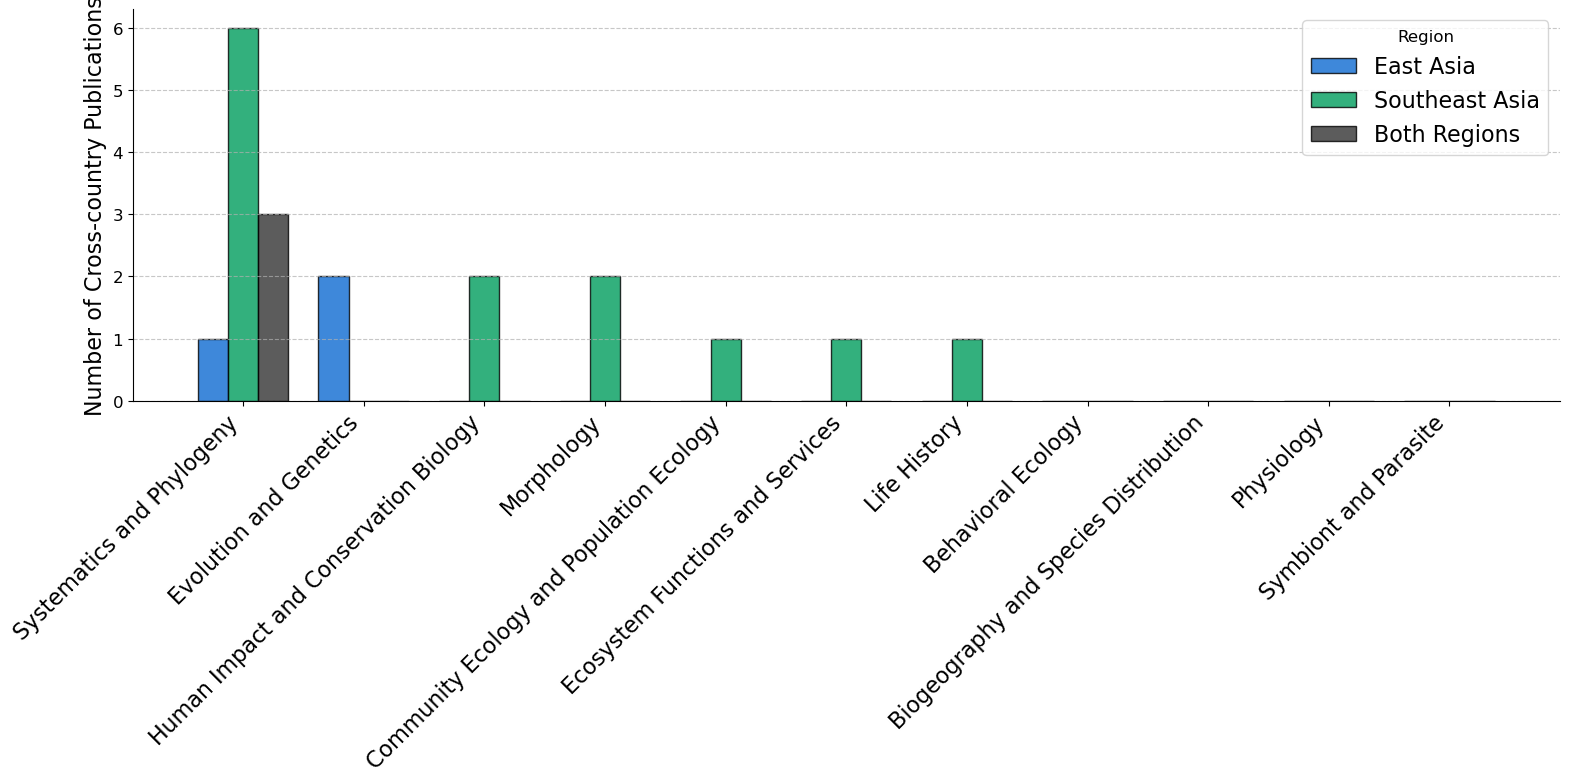

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 22
plt.rcParams['font.family'] = 'Arial'


# 1. Load the data 
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

# 2. Identify collaborative publications 
# If the sum of country columns is 2 or more, it's an international collaboration
country_cols = [col for col in df.columns if str(col).startswith('Country_')]
df['Is_Collaboration'] = df[country_cols].sum(axis=1) >= 2

# 3. Create region labels 
# Classify into East Asia only, Southeast Asia only, or Both
def get_region_category(row):
    ea = row.get('Region_East Asia', 0)
    sea = row.get('Region_Southeast Asia', 0)
    if ea == 1 and sea == 1:
        return 'Both Regions'
    elif ea == 1:
        return 'East Asia'
    elif sea == 1:
        return 'Southeast Asia'
    else:
        return 'Other'

# Apply region category to all data
df['Region_Category'] = df.apply(get_region_category, axis=1)

# 4. Extract research topics 
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]

# 5. Aggregate by region for each topic 
summary_data = []
for topic in topic_cols:
    # Extract collaborative papers with the current topic 
    subset = df[(df[topic] == 1) & (df['Is_Collaboration'] == True)]
    counts = subset['Region_Category'].value_counts()
    
    clean_name = topic.replace('Research topic_', '')
    
    summary_data.append({
        'Topic': clean_name,
        'East Asia': counts.get('East Asia', 0),
        'Southeast Asia': counts.get('Southeast Asia', 0),
        'Both Regions': counts.get('Both Regions', 0),
        'Total': len(subset) # Total collaborative papers for sorting 
    })

df_summary = pd.DataFrame(summary_data)

# Sort descending by total, keeping topics with 0 collaborations
df_summary = df_summary.sort_values(by=['Total', 'Topic'], ascending=[False, True])

# 6. Plotting the grouped bar chart 
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'sans-serif'
fig, ax = plt.subplots(figsize=(16, 8))

# Convert data to lists for plotting
x_labels = df_summary['Topic'].tolist()
ea_counts = df_summary['East Asia'].values
sea_counts = df_summary['Southeast Asia'].values
both_counts = df_summary['Both Regions'].values

x = np.arange(len(x_labels)) # X-axis positions 
width = 0.25 # Bar width 

# Draw grouped bars (shifting X positions) 
ax.bar(x - width, ea_counts, width, label='East Asia', color='#0E6BD1', edgecolor='black', alpha=0.8)
ax.bar(x, sea_counts, width, label='Southeast Asia', color='#009D5C', edgecolor='black', alpha=0.8)
ax.bar(x + width, both_counts, width, label='Both Regions', color='#333333', edgecolor='black', alpha=0.8)

ax.set_ylabel('Number of Cross-country Publications', fontsize=16)

ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=16)
ax.legend(title='Region', fontsize=16)

# Add horizontal grid lines and remove top/right spines 
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('topic_collaboration_grouped_bar.png', dpi=600)
plt.show()

Fig. S9

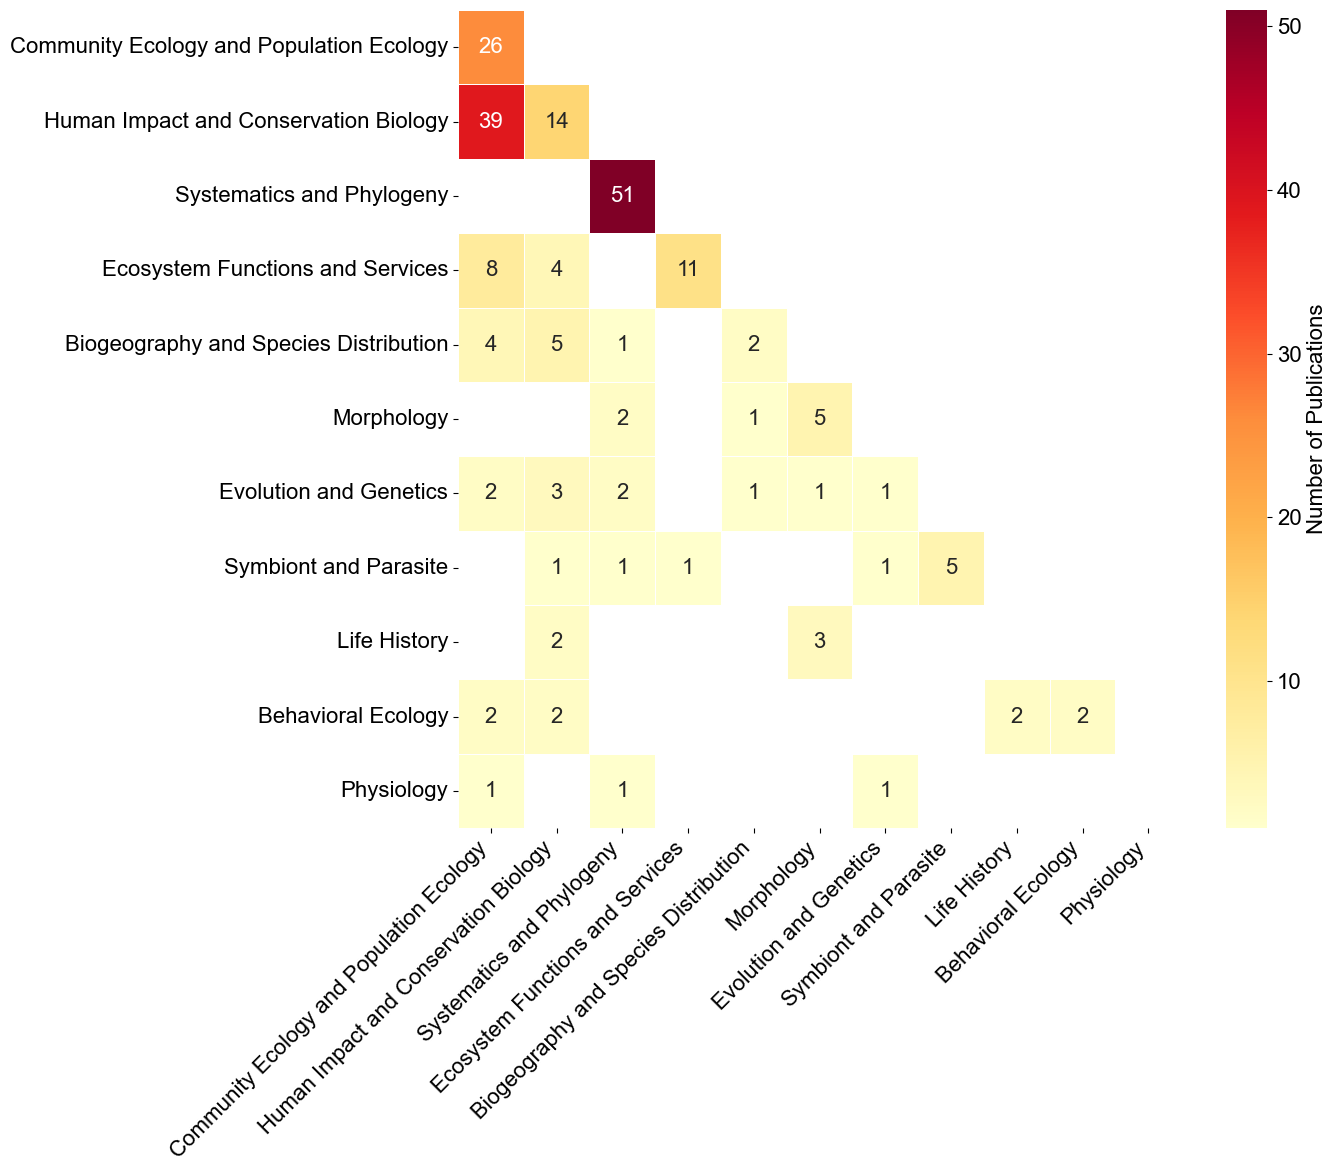

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Arial'


file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

# Extract only Research topic columns 
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]
df_topics = df[topic_cols].fillna(0)

# --- Sort topics by total publications 
topic_totals = df_topics.sum().sort_values(ascending=False)
sorted_topics = topic_totals.index.tolist()

df_topics = df_topics[sorted_topics]

# Calculate co-occurrence matrix 
co_matrix = df_topics.T.dot(df_topics)

# Calculate single-topic publications for the diagonal 
for col in df_topics.columns:
    single_count = len(df_topics[(df_topics[col] == 1) & (df_topics.sum(axis=1) == 1)])
    co_matrix.loc[col, col] = single_count

# Clean up column and index names 
co_matrix.index = [c.replace('Research topic_', '') for c in co_matrix.index]
co_matrix.columns = [c.replace('Research topic_', '') for c in co_matrix.columns]

# --- Create the heatmap 
plt.figure(figsize=(14, 12)) 
upper_mask = np.triu(np.ones_like(co_matrix, dtype=bool), k=1)

mask = (co_matrix == 0) | upper_mask

sns.heatmap(co_matrix, cmap='YlOrRd', annot=True, fmt='g', 
            linewidths=.5, cbar_kws={'label': 'Number of Publications'},
            mask=mask)



# Rotate x-axis labels 
plt.xticks(rotation=45, ha='right')

# Adjust layout and show 
plt.tight_layout()
plt.show()

Fig. 3a

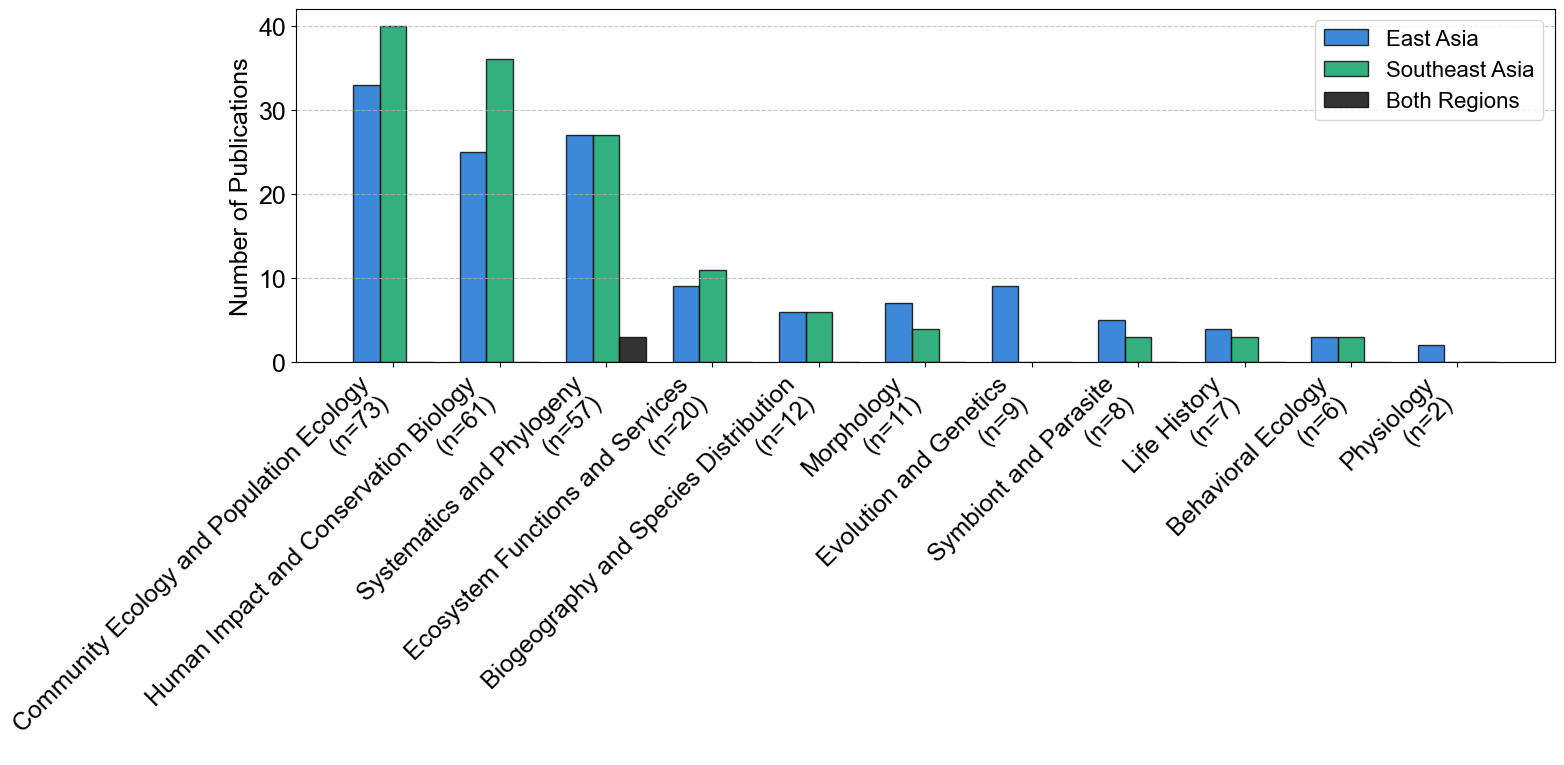

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 18
plt.rcParams['font.family'] = 'Arial'


# ==========================================
# 1. Load Data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# ==========================================
# 2. Extract Research Topics and Determine Order
# ==========================================
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]


topic_counts = df[topic_cols].sum().sort_values(ascending=False)
topic_counts = topic_counts[topic_counts > 0]
ordered_topics = topic_counts.index.tolist()

topic_labels = [f"{label.replace('Research topic_', '')}\n(n={int(topic_counts[label])})" for label in ordered_topics]

# ==========================================
# 3. Determine Region Labels for each paper
# ==========================================
def get_region_label(row):
    ea = row.get('Region_East Asia', 0)
    sea = row.get('Region_Southeast Asia', 0)
    if ea == 1 and sea == 1:
        return 'Both'
    elif ea == 1 and sea == 0:
        return 'East Asia'
    elif ea == 0 and sea == 1:
        return 'Southeast Asia'
    else:
        return 'Other'

df['Region_Label'] = df.apply(get_region_label, axis=1)

# ==========================================
# 4. Prepare data for grouped bar chart
# ==========================================
ea_counts = []
sea_counts = []
both_counts = []

for topic in ordered_topics:

    subset = df[df[topic] == 1]
    
    counts = subset['Region_Label'].value_counts()
    
    ea_counts.append(counts.get('East Asia', 0))
    sea_counts.append(counts.get('Southeast Asia', 0))
    both_counts.append(counts.get('Both', 0))


ea_counts = np.array(ea_counts)
sea_counts = np.array(sea_counts)
both_counts = np.array(both_counts)

# ==========================================
# 5. Plotting (Grouped Bar Chart)
# ==========================================
plt.rcParams['font.family'] = 'Arial' 
fig, ax = plt.subplots(figsize=(16, 8))

# Setting X-axis position
x = np.arange(len(topic_labels)) 
width = 0.25  

ax.bar(x - width, ea_counts, width, label='East Asia', color='#0E6BD1', edgecolor='black', alpha=0.8)
ax.bar(x, sea_counts, width, label='Southeast Asia', color='#009D5C', edgecolor='black', alpha=0.8)
ax.bar(x + width, both_counts, width, label='Both Regions', color='black', edgecolor='black', alpha=0.8)


ax.set_ylabel('Number of Publications', fontsize=18)

ax.set_xticks(x)
ax.set_xticklabels(topic_labels, rotation=45, ha='right', fontsize=18)

ax.legend(fontsize=16, title_fontsize=12)


ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('topic_grouped_counts.png', dpi=600)
plt.show()

Fig.3 b,c

c:\Users\r-aka\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


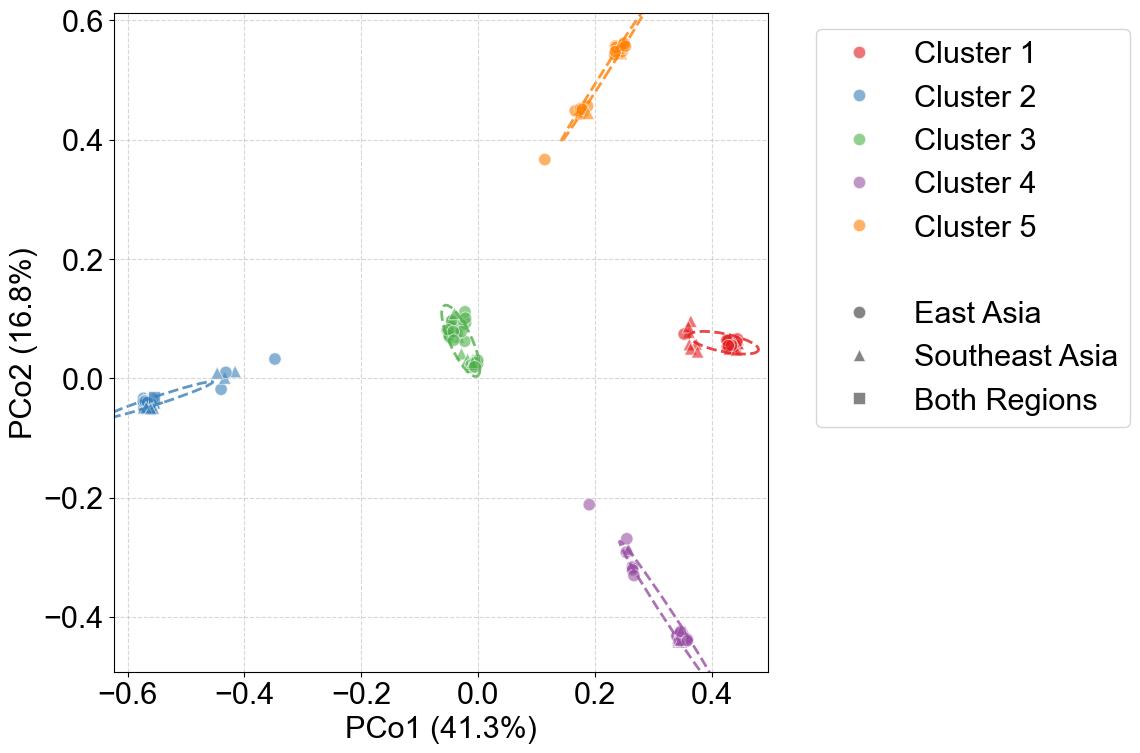

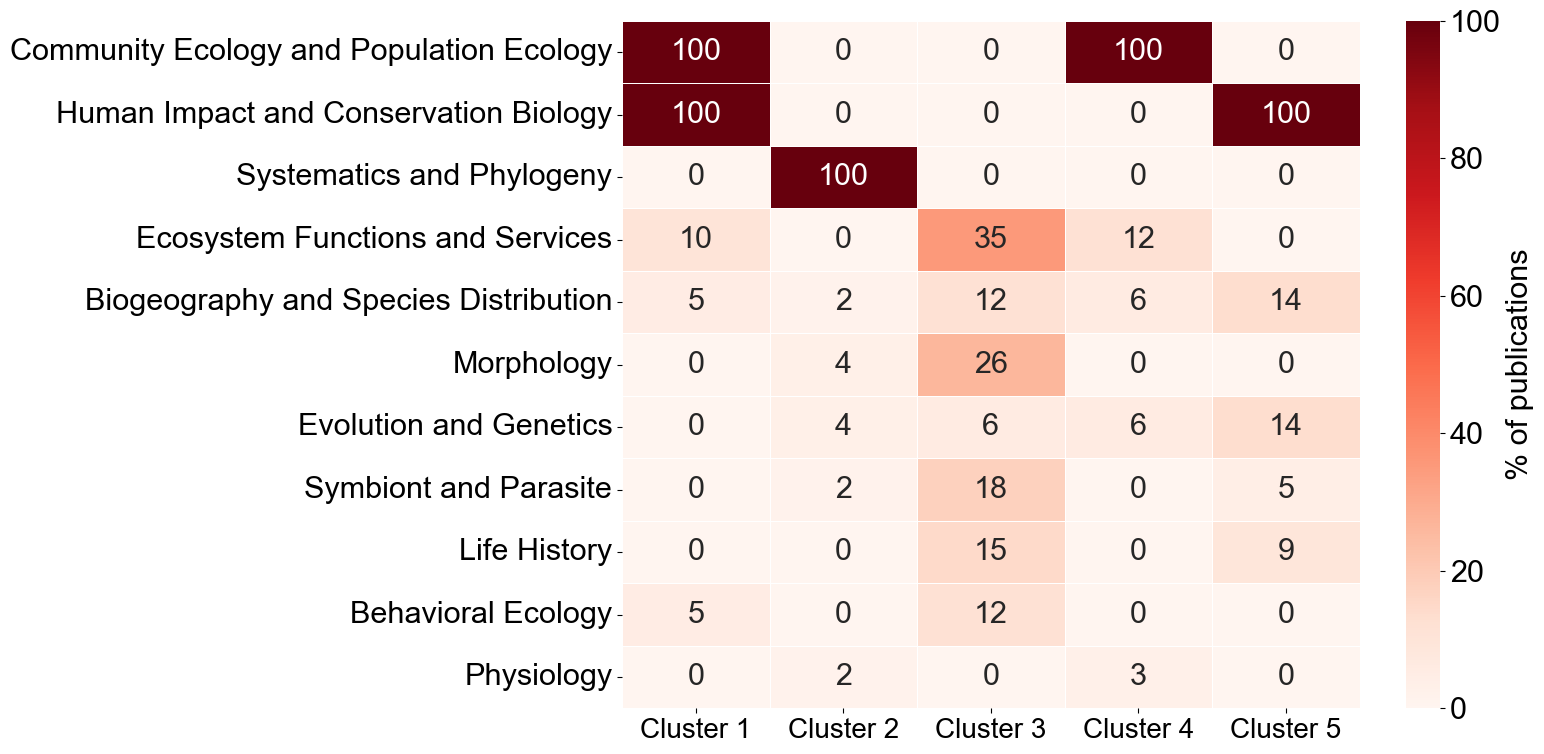

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms
import matplotlib.lines as mlines  # Required for legend customization 

# Set global font size and family 
plt.rcParams['font.size'] = 22
plt.rcParams['font.family'] = 'Arial'


# ==========================================
# Function Definitions 
# ==========================================

def confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
    if x.size != y.size:
        raise ValueError("x and y must be the same size")
    
    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)
    
    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    
    transf = transforms.Affine2D() \
        .rotate_deg(45) \
        .scale(scale_x, scale_y) \
        .translate(np.mean(x), np.mean(y))
    
    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)


# ==========================================
# Main Processing 
# ==========================================

# 1. Load data 
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)
df = df[(df['Publication Year'] >= 1980)]

# 2. Extract topics and select valid data 
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]
df['topic_sum'] = df[topic_cols].sum(axis=1)
df_valid = df[df['topic_sum'] > 0].copy()

# 3. Jaccard distance and PCoA 
X = df_valid[topic_cols].values
dist_array = pdist(X, metric='jaccard')
dist_matrix = squareform(dist_array)

# Create centering matrix 
D_sq = dist_matrix ** 2
n = D_sq.shape[0]
H = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * H.dot(D_sq).dot(H)

# Calculate and sort eigenvalues/eigenvectors 
eigenvalues, eigenvectors = np.linalg.eigh(B)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Correct negative eigenvalues 
eigenvalues[eigenvalues < 0] = 0

# Calculate explained variance 
total_variance = np.sum(eigenvalues)
pco1_var = (eigenvalues[0] / total_variance) * 100
pco2_var = (eigenvalues[1] / total_variance) * 100

# Calculate PCoA coordinates 
coords = eigenvectors[:, :2] * np.sqrt(eigenvalues[:2])
df_valid['PCo1'] = coords[:, 0]
df_valid['PCo2'] = coords[:, 1]

# --- Add Jitter 
x_range = df_valid['PCo1'].max() - df_valid['PCo1'].min()
y_range = df_valid['PCo2'].max() - df_valid['PCo2'].min()
jitter_factor = 0.01

np.random.seed(42)
df_valid['PCo1_jittered'] = df_valid['PCo1'] + np.random.uniform(-x_range * jitter_factor, x_range * jitter_factor, size=len(df_valid))
df_valid['PCo2_jittered'] = df_valid['PCo2'] + np.random.uniform(-y_range * jitter_factor, y_range * jitter_factor, size=len(df_valid))

# 4. K-means clustering 
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_valid['Cluster'] = kmeans.fit_predict(coords)
df_valid['Cluster'] = 'Cluster ' + (df_valid['Cluster'] + 1).astype(str)
cluster_order = sorted(df_valid['Cluster'].unique())

# 5. Assign region labels 
cond_both = (df_valid.get('Region_East Asia', 0) == 1) & (df_valid.get('Region_Southeast Asia', 0) == 1)
cond_ea = (df_valid.get('Region_East Asia', 0) == 1) & (df_valid.get('Region_Southeast Asia', 0) == 0)
cond_sea = (df_valid.get('Region_East Asia', 0) == 0) & (df_valid.get('Region_Southeast Asia', 0) == 1)

conditions = [cond_both, cond_ea, cond_sea]
choices = ['Both Regions', 'East Asia', 'Southeast Asia']
df_valid['Region_Label'] = np.select(conditions, choices, default='Outside EA/SEA')

region_order = ['East Asia', 'Southeast Asia', 'Both Regions']
region_markers = {'East Asia': 'o', 'Southeast Asia': '^', 'Both Regions': 's'}
if 'Outside EA/SEA' in df_valid['Region_Label'].values:
    region_order.append('Outside EA/SEA')
    region_markers['Outside EA/SEA'] = 'D'

palette = sns.color_palette("Set1", n_colors=n_clusters)
color_dict = dict(zip(cluster_order, palette))


# ==========================================
# Plot 1: PCoA Scatter Plot 
# ==========================================
# Create a new figure for Plot 1 
fig1, ax1 = plt.subplots(figsize=(12, 8))

sns.scatterplot(data=df_valid, x='PCo1_jittered', y='PCo2_jittered', 
                hue='Cluster', hue_order=cluster_order, palette=color_dict,
                style='Region_Label', style_order=region_order, markers=region_markers,
                alpha=0.6, edgecolor='w', s=80, ax=ax1) 

# Draw ellipses for each cluster 
for cluster_name in cluster_order:
    cluster_data = df_valid[df_valid['Cluster'] == cluster_name]
    x_val = cluster_data['PCo1'].values
    y_val = cluster_data['PCo2'].values
    
    if len(x_val) > 2:
        confidence_ellipse(x_val, y_val, ax1, n_std=2.0, 
                           edgecolor=color_dict[cluster_name], facecolor='none', 
                           linestyle='--', linewidth=2.0, alpha=0.8)

ax1.set_xlabel(f'PCo1 ({pco1_var:.1f}%)')
ax1.set_ylabel(f'PCo2 ({pco2_var:.1f}%)')
ax1.grid(True, linestyle='--', alpha=0.5)

# Customize legend 
handles, labels = ax1.get_legend_handles_labels()
new_handles = []
new_labels = []

for h, l in zip(handles, labels):
    if l == 'Cluster':
        continue # Skip 'Cluster' 
    elif l == 'Region_Label':
        # Replace with a blank line 
        blank_line = mlines.Line2D([], [], color='none', marker='None', label='')
        new_handles.append(blank_line)
        new_labels.append('')
    else:
        new_handles.append(h)
        new_labels.append(l)

ax1.legend(handles=new_handles, labels=new_labels, bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust layout and save Plot 1 
fig1.tight_layout()
fig1.savefig('Fig_PCoA.png', dpi=600)


# ==========================================
# Plot 2: Topic Profiling Heatmap 
# ==========================================
# Calculate percentages 
cluster_counts = df_valid['Cluster'].value_counts()
topic_sums_by_cluster = df_valid.groupby('Cluster')[topic_cols].sum()
topic_percentages = topic_sums_by_cluster.div(cluster_counts, axis=0) * 100

# Format column names 
topic_percentages.columns = [c.replace('Research topic_', '') for c in topic_percentages.columns]

# Sort topics by total count 
total_topic_counts = df_valid[topic_cols].sum().sort_values(ascending=False)
ordered_topics = [c.replace('Research topic_', '') for c in total_topic_counts.index]
topic_percentages_t = topic_percentages.T.reindex(ordered_topics)

# Create a new figure for Plot 2 
fig2, ax2 = plt.subplots(figsize=(16, 8))

# Draw heatmap 
sns.heatmap(topic_percentages_t[cluster_order], cmap='Reds', annot=True, fmt='.0f', 
            linewidths=.5, cbar_kws={'label': '% of publications'}, 
            vmin=0, vmax=100, ax=ax2)


ax2.set_xlabel('')
ax2.set_ylabel('')

ax2.tick_params(axis='x', labelsize=20)

fig2.tight_layout()
fig2.savefig('Fig_Heatmap.png', dpi=600)

plt.show()

Fig. S10


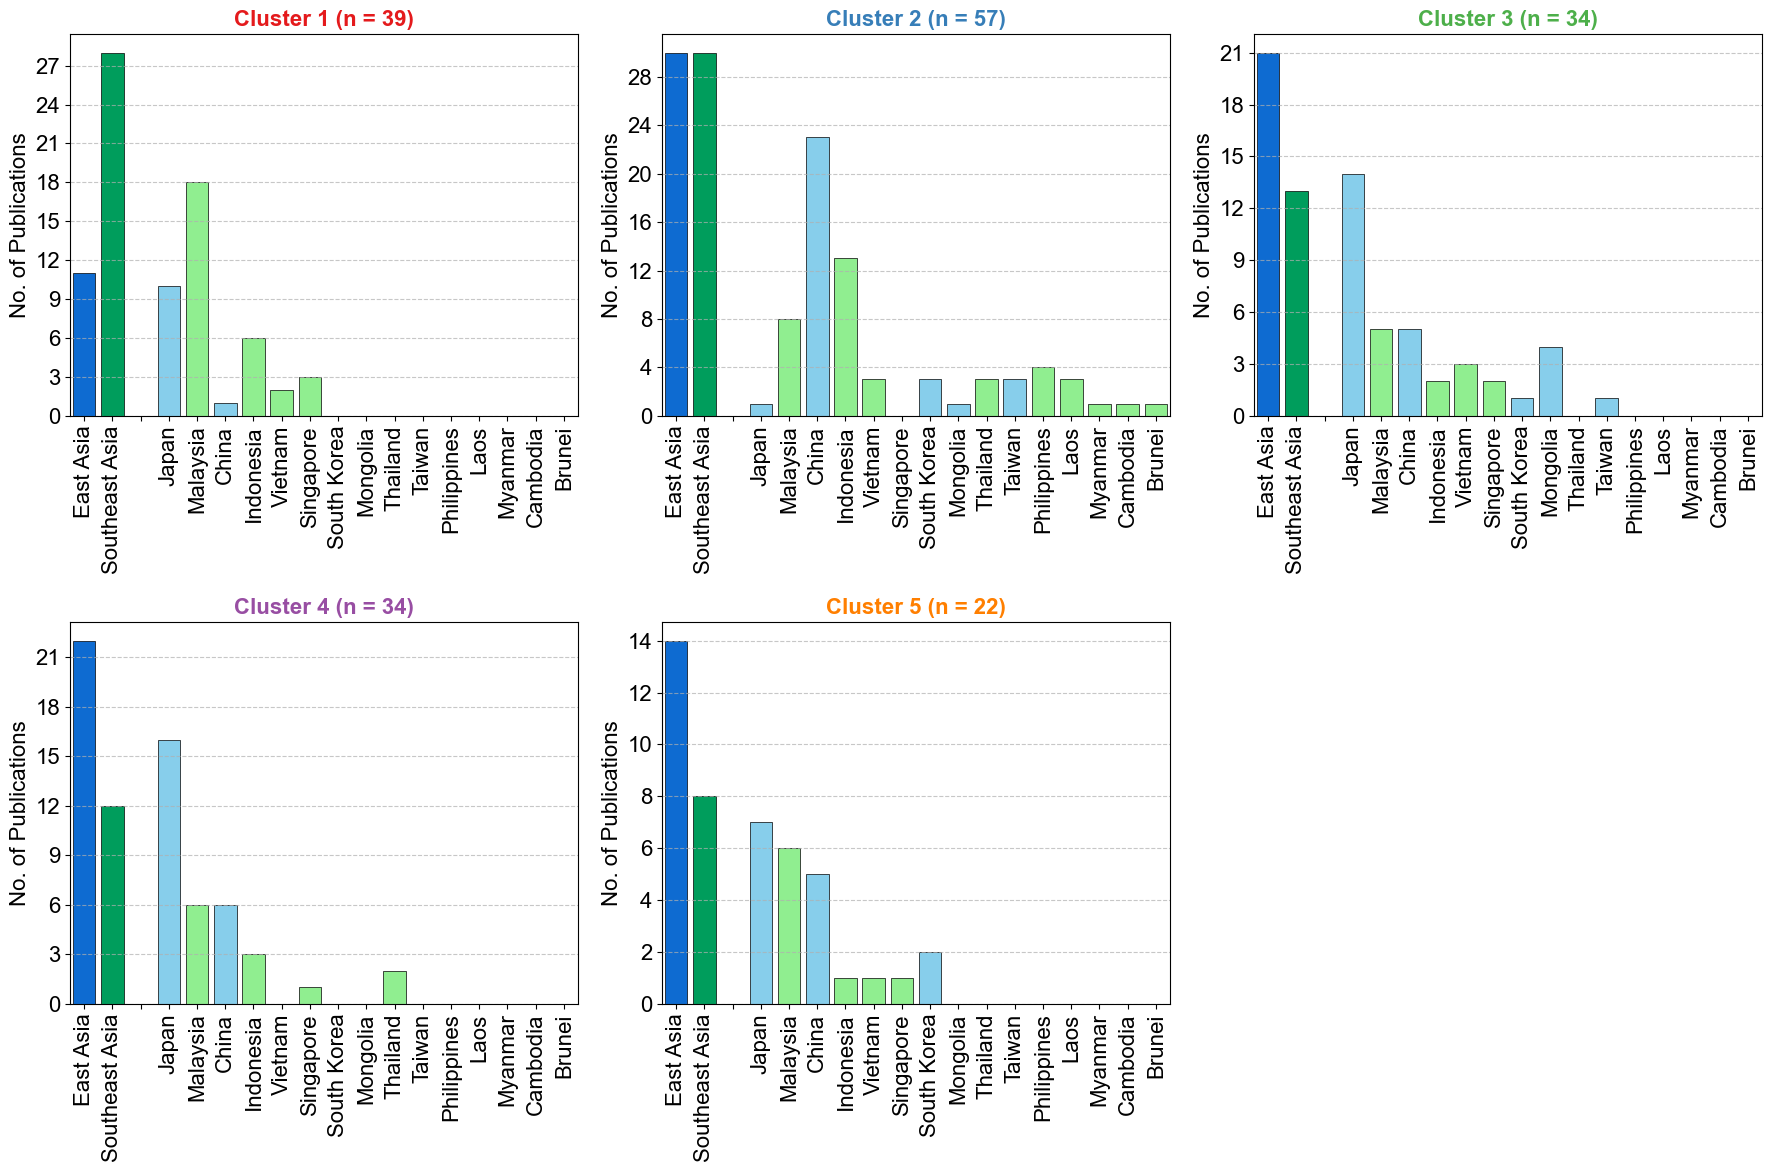

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from matplotlib.ticker import MaxNLocator
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans

plt.rcParams['font.size'] = 16


# ==========================================
# 1. Loading data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

# ==========================================
# 2. Clustering
# ==========================================
topic_cols = [col for col in df.columns if str(col).startswith('Research topic_')]
df['topic_sum'] = df[topic_cols].sum(axis=1)
df_valid = df[df['topic_sum'] > 0].copy()

# Calculate PCoA
X = df_valid[topic_cols].values
dist_array = pdist(X, metric='jaccard')
dist_matrix = squareform(dist_array)

D_sq = dist_matrix ** 2
n = D_sq.shape[0]
H = np.eye(n) - np.ones((n, n)) / n
B = -0.5 * H.dot(D_sq).dot(H)

eigenvalues, eigenvectors = np.linalg.eigh(B)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]
eigenvalues[eigenvalues < 0] = 0
coords = eigenvectors[:, :2] * np.sqrt(eigenvalues[:2])

# K-means
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_valid['Cluster'] = kmeans.fit_predict(coords)
df_valid['Cluster'] = 'Cluster ' + (df_valid['Cluster'] + 1).astype(str)
cluster_order = sorted(df_valid['Cluster'].unique())

# ==========================================
# 3. X-axis set up
# ==========================================
target_regions = ['Region_East Asia', 'Region_Southeast Asia']
regions_present = [col for col in target_regions if col in df_valid.columns]

country_cols = [col for col in df_valid.columns if str(col).startswith('Country_')]
country_totals_dict = {col: df_valid[col].sum() for col in country_cols}
sorted_countries = [col for col, val in sorted(country_totals_dict.items(), key=lambda x: x[1], reverse=True) if val > 0]

ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

x_labels = []
x_cols = []
bar_colors = []


for col in regions_present:
    x_labels.append(col.replace('Region_', ''))
    x_cols.append(col)
    bar_colors.append('#0E6BD1' if 'East Asia' in col else '#009D5C')


x_labels.append('')
x_cols.append(None)
bar_colors.append('white')

for col in sorted_countries:
    c_name = col.replace('Country_', '')
    x_labels.append(c_name)
    x_cols.append(col)
    if c_name in ea_countries:
        bar_colors.append('skyblue')
    elif c_name in sea_countries:
        bar_colors.append('lightgreen')
    else:
        bar_colors.append('lightgray')

# ==========================================
# 4. Plotting
# ==========================================
cols_per_row = 3
n_rows = math.ceil(n_clusters / cols_per_row)
fig, axes = plt.subplots(n_rows, cols_per_row, figsize=(18, 6 * n_rows))
axes = axes.flatten()


palette = sns.color_palette("Set1", n_colors=n_clusters)
color_dict = dict(zip(cluster_order, palette))

for i, cluster in enumerate(cluster_order):
    ax = axes[i]
    
    subset = df_valid[df_valid['Cluster'] == cluster]
    
    y_values = []
    for x_col in x_cols:
        if x_col is None:
            y_values.append(0)
        else:
            y_values.append(subset[x_col].sum())
            
    x_pos = range(len(x_labels))
    ax.bar(x_pos, y_values, color=bar_colors, edgecolor='black', linewidth=0.5)
    

    c_color = color_dict[cluster]
    ax.set_title(f'{cluster} (n = {len(subset)})', fontsize=16, fontweight='bold', color=c_color)
    ax.set_ylabel('No. of Publications', fontsize=16)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=16)
    
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_xlim(-0.5, len(x_labels) - 0.5)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('FigS.png', dpi=600)
plt.show()

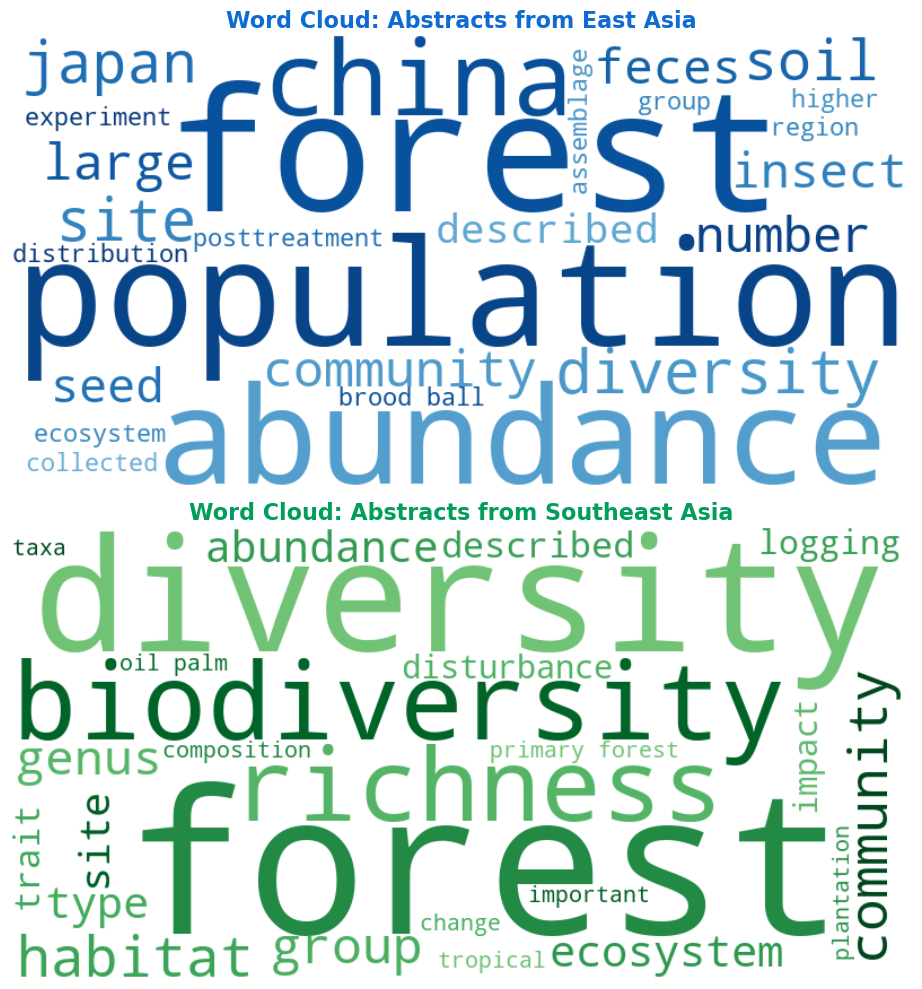

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors 
from wordcloud import WordCloud, STOPWORDS
import re

file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


df = df.dropna(subset=['Abstract'])

def clean_text(text):
    text = str(text).lower()                 
    text = re.sub(r'[^a-z\s]', '', text)     
    return text

def clean_text(text):
    text = str(text).lower() 
    
    text = re.sub(r'\bcommunities\b', 'community', text)
    text = re.sub(r'\bseeds\b', 'seed', text)


    text = re.sub(r'[^a-z\s]', '', text) 
    
    return text


ea_texts = df[df['Region_East Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')
sea_texts = df[df['Region_Southeast Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')

# 3. Setting stop words
custom_stopwords = set(STOPWORDS)
academic_words = [
    'study', 'studies', 'species', 'result', 'results', 'showed', 'using', 'also', 'may', 
    'two', 'one', "three", "four", "five", "six", "seven", "eight", "nine", "ten",
    'new', 'found', 'effect', 'effects',  
    'analysis', 'data', 'different', 'used', 'can', 'will', 'based', 'time', 'year',
    'years', 'area', 'areas', 'however', 'significant', 'significantly', 'among', 'within',
    'research', 'paper', 'article', 'review',
    "compared",
    "0","o", "."
    "day", "days",
    "dung", "beetle", "beetles"

]
。
custom_stopwords.update(academic_words)
def truncate_colormap(cmap_name, minval=0.4, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    new_cmap = mcolors.LinearSegmentedColormap.from_list(
        f'trunc({cmap_name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

cmap_blues_dark = truncate_colormap('Blues', minval=0.5)
cmap_greens_dark = truncate_colormap('Greens', minval=0.5)
# ----------------------------------------

word_max = 25

# 4. Generating word cloud.
wc_ea = WordCloud(width=800, height=400, background_color='white', 
                  colormap=cmap_blues_dark, stopwords=custom_stopwords, 
                  max_words=word_max).generate(ea_texts)

wc_sea = WordCloud(width=800, height=400, background_color='white', 
                   colormap=cmap_greens_dark, stopwords=custom_stopwords, 
                   max_words=word_max).generate(sea_texts)



# 5. Plotting graph
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# East Asia
axes[0].imshow(wc_ea, interpolation='bilinear')
axes[0].set_title('Word Cloud: Abstracts from East Asia', fontsize=16, fontweight='bold', color='#0E6BD1')
axes[0].axis('off') 

# Southeast Asia
axes[1].imshow(wc_sea, interpolation='bilinear')
axes[1].set_title('Word Cloud: Abstracts from Southeast Asia', fontsize=16, fontweight='bold', color='#009D5C')
axes[1].axis('off')

plt.tight_layout()
plt.show()

Fig. 4

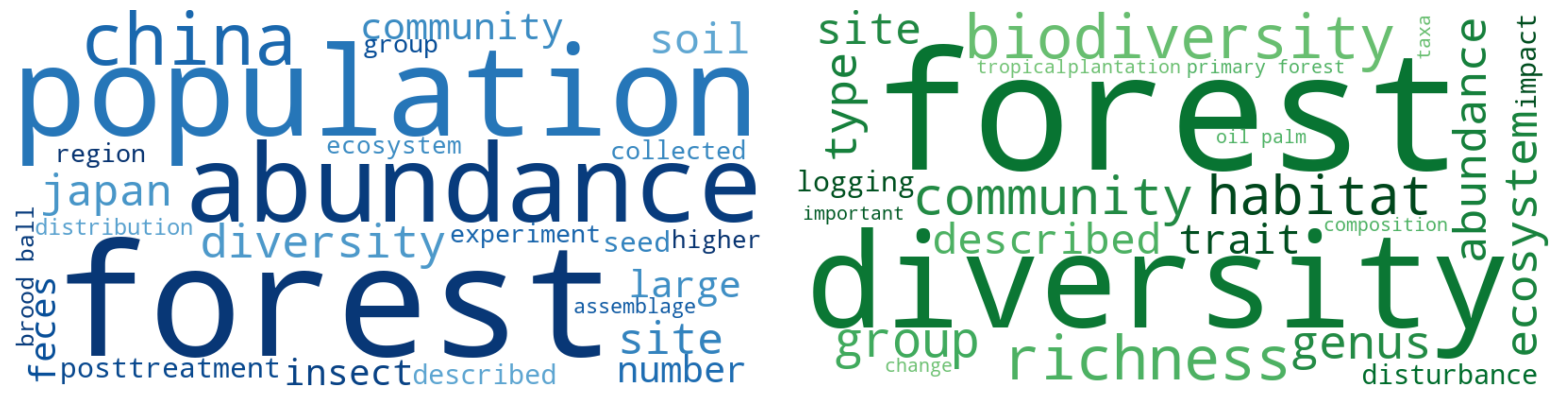

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from wordcloud import WordCloud, STOPWORDS
import re

# 1. Loading data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


df = df.dropna(subset=['Abstract'])

# 2. text cleansing
def clean_text(text):
    text = str(text).lower() 
    
    text = re.sub(r'\bcommunities\b', 'community', text)
    text = re.sub(r'\bseeds\b', 'seed', text)

    text = re.sub(r'[^a-z\s]', '', text) 
    
    return text


ea_texts = df[df['Region_East Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')
sea_texts = df[df['Region_Southeast Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')

# 3. Setting stop words
custom_stopwords = set(STOPWORDS)
academic_words = [
    'study', 'studies', 'species', 'result', 'results', 'showed', 'using', 'also', 'may', 
    'two', 'one', "three", "four", "five", "six", "seven", "eight", "nine", "ten",
    'new', 'found', 'effect', 'effects',  
    'analysis', 'data', 'different', 'used', 'can', 'will', 'based', 'time', 'year',
    'years', 'area', 'areas', 'however', 'significant', 'significantly', 'among', 'within',
    'research', 'paper', 'article', 'review',
    "compared","described"
    "0", "o", "day", "days", "dung", "beetle", "beetles"
]
custom_stopwords.update(academic_words)


def truncate_colormap(cmap_name, minval=0.4, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    new_cmap = mcolors.LinearSegmentedColormap.from_list(
        f'trunc({cmap_name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

cmap_blues_dark = truncate_colormap('Blues', minval=0.5)
cmap_greens_dark = truncate_colormap('Greens', minval=0.5)

word_max = 25

# 4. Generating word cloud
wc_ea = WordCloud(width=800, height=400, background_color='white', 
                  colormap=cmap_blues_dark, stopwords=custom_stopwords, 
                  max_words=word_max).generate(ea_texts)

wc_sea = WordCloud(width=800, height=400, background_color='white', 
                   colormap=cmap_greens_dark, stopwords=custom_stopwords, 
                   max_words=word_max).generate(sea_texts)

# ==========================================
# 5. Generate figure.
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 10))


axes[0].imshow(wc_ea, interpolation='bilinear')
axes[0].axis('off')

axes[1].imshow(wc_sea, interpolation='bilinear')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('wordcloud_side_by_side.png', dpi=600)
plt.show()

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from wordcloud import WordCloud, STOPWORDS
import re

# 1. Loading data
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)

df = df.dropna(subset=['Abstract'])

# 2. Cleansing text
def clean_text(text):
    text = str(text).lower() 
    
    text = re.sub(r'\bcommunities\b', 'community', text)
    text = re.sub(r'\bseeds\b', 'seed', text)

    text = re.sub(r'[^a-z\s]', '', text) 
    
    return text

ea_texts = df[df['Region_East Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')
sea_texts = df[df['Region_Southeast Asia'] == 1]['Abstract'].apply(clean_text).str.cat(sep=' ')

# 3. Setting stop words
custom_stopwords = set(STOPWORDS)
academic_words = [
    'study', 'studies', 'species', 'result', 'results', 'showed', 'using', 'also', 'may', 
    'two', 'one', "three", "four", "five", "six", "seven", "eight", "nine", "ten",
    'new', 'found', 'effect', 'effects',  
    'analysis', 'data', 'different', 'used', 'can', 'will', 'based', 'time', 'year',
    'years', 'area', 'areas', 'however', 'significant', 'significantly', 'among', 'within',
    'research', 'paper', 'article', 'review',
    "compared","described",
    "0", "o", "day", "days", "dung", "beetle", "beetles"
]
custom_stopwords.update(academic_words)


def truncate_colormap(cmap_name, minval=0.4, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    new_cmap = mcolors.LinearSegmentedColormap.from_list(
        f'trunc({cmap_name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

cmap_blues_dark = truncate_colormap('Blues', minval=0.5)
cmap_greens_dark = truncate_colormap('Greens', minval=0.5)

word_max = 25

# 4. Generating wordcloud
wc_ea = WordCloud(width=800, height=400, background_color='white', 
                  colormap=cmap_blues_dark, stopwords=custom_stopwords, 
                  max_words=word_max).generate(ea_texts)

wc_sea = WordCloud(width=800, height=400, background_color='white', 
                   colormap=cmap_greens_dark, stopwords=custom_stopwords, 
                   max_words=word_max).generate(sea_texts)

# ==========================================
# 5. Illutrating graph
# ==========================================



# ==========================================
# 6. Makign data frame
# ==========================================
ea_words = list(wc_ea.words_.keys())
sea_words = list(wc_sea.words_.keys())


df_words = pd.DataFrame({
    'Rank': range(1, word_max + 1),
    'East Asia': ea_words,
    'Southeast Asia': sea_words
})

# print output
print("\n=== Top 25 Frequent Words by Region ===")
print(df_words.to_string(index=False))

# Making csv
df_words.to_csv('top_words_by_region.csv', index=False)
print("\nCSVファイル 'top_words_by_region.csv' に保存しました。")


=== Top 25 Frequent Words by Region ===
 Rank     East Asia Southeast Asia
    1        forest         forest
    2    population      diversity
    3     abundance   biodiversity
    4         china       richness
    5     diversity        habitat
    6          site      community
    7         japan          group
    8          soil          genus
    9     community      ecosystem
   10         large           type
   11        number      abundance
   12         feces           site
   13        insect          trait
   14 posttreatment        logging
   15          seed         impact
   16    experiment    disturbance
   17        region primary forest
   18     collected      important
   19         group         change
   20     ecosystem           taxa
   21        higher       tropical
   22    brood ball    composition
   23  distribution     plantation
   24    assemblage       oil palm
   25        sp nov           high

CSVファイル 'top_words_by_region.csv' に保存しました。


Figure S11

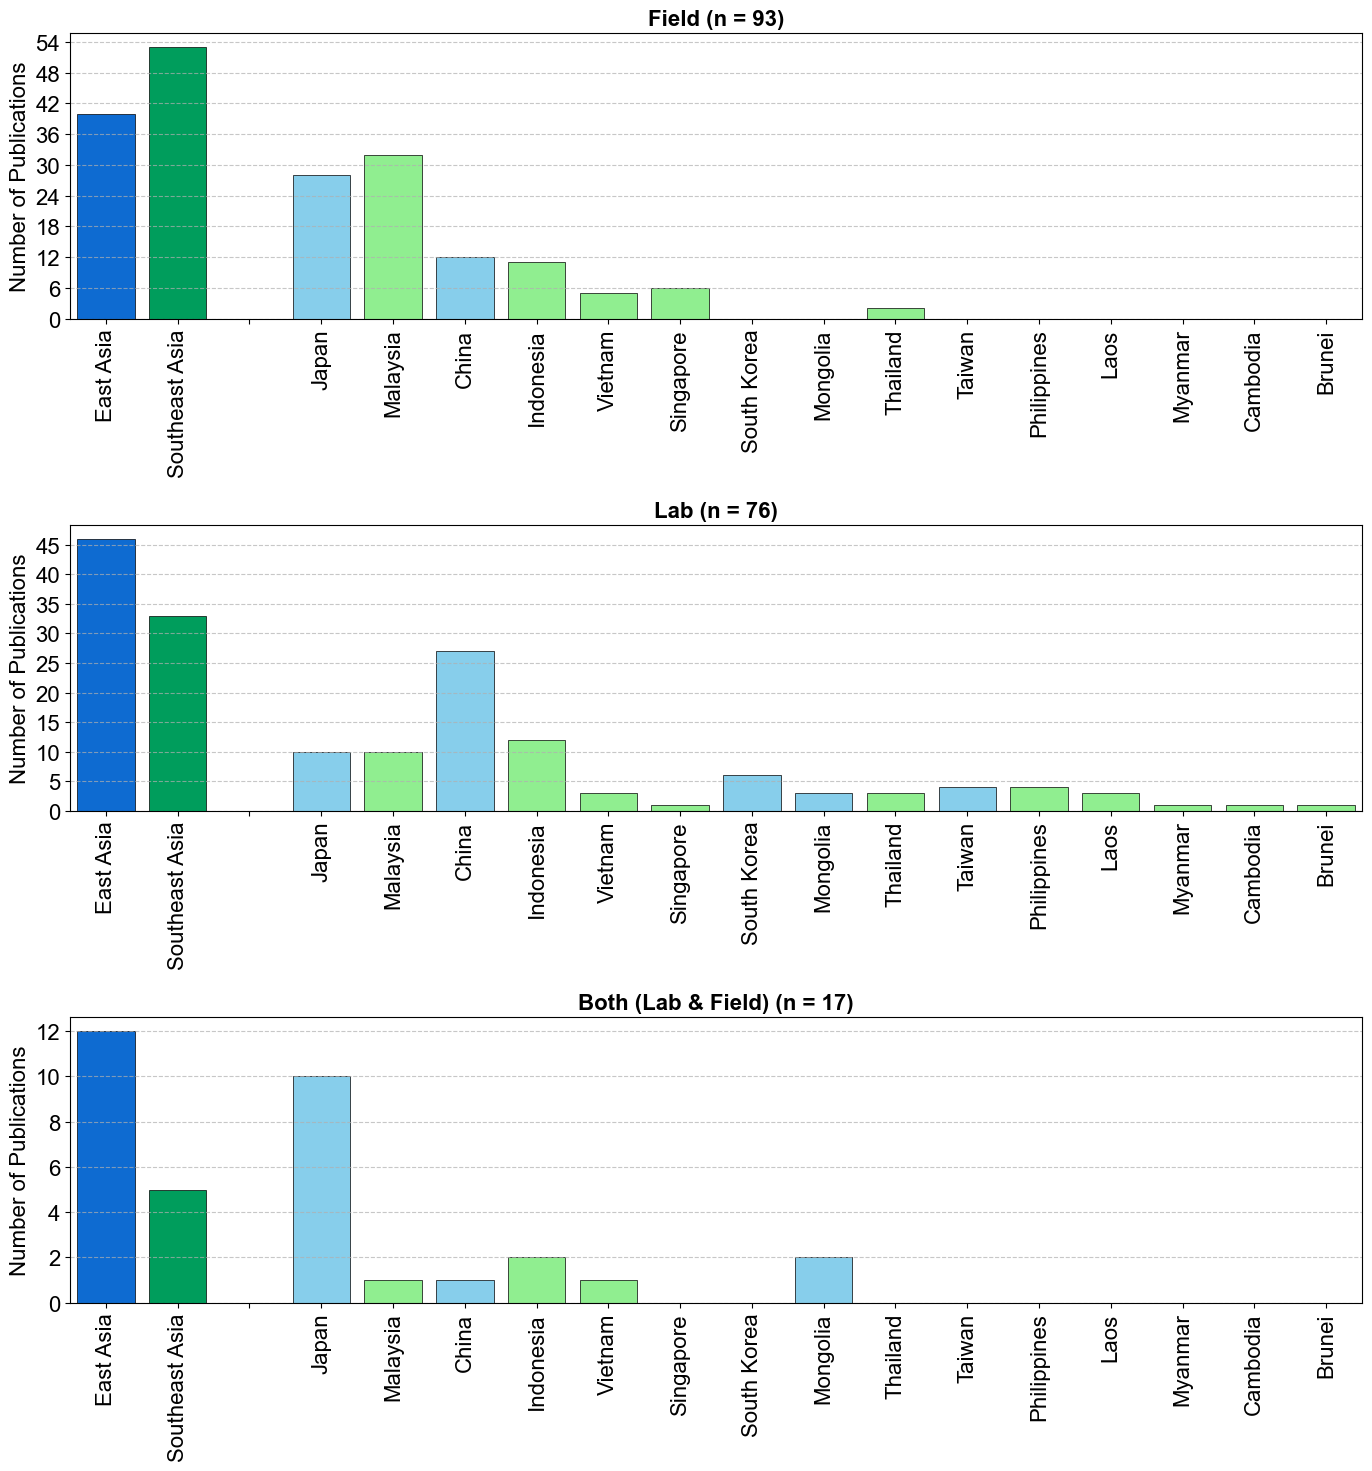

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams['font.size'] = 16
plt.rcParams['font.family'] = 'Arial'


# ==========================================
# 1. Loading data
# ==========================================
file_path = 'DB_Review_EASEA_data.csv'
df = pd.read_csv(file_path)


# ==========================================
# 2. Study Setting (Lab / Field / Both) 
# ==========================================
def get_study_setting(row):
    is_field = row.get('Lab or Field work_Field', 0)
    is_lab = row.get('Lab or Field work_Lab', 0)
    
    if is_field == 1 and is_lab == 1:
        return 'Both (Lab & Field)'
    elif is_field == 1:
        return 'Field'
    elif is_lab == 1:
        return 'Lab'
    else:
        return 'Other/Unspecified'

df['Study_Setting'] = df.apply(get_study_setting, axis=1)


settings = ['Field', 'Lab', 'Both (Lab & Field)']

# ==========================================
# 3. Making X-axis
# ==========================================
target_regions = ['Region_East Asia', 'Region_Southeast Asia']
regions_present = [col for col in target_regions if col in df.columns]

country_cols = [col for col in df.columns if str(col).startswith('Country_')]
country_totals_dict = {col: df[col].sum() for col in country_cols}

# Sorting
sorted_countries = [col for col, val in sorted(country_totals_dict.items(), key=lambda x: x[1], reverse=True) if val > 0]

ea_countries = ['China', 'Japan', 'Taiwan', 'South Korea', 'Mongolia']
sea_countries = ['Malaysia', 'Singapore', 'Indonesia', 'Vietnam', 'Laos', 'Thailand', 'Myanmar', 'Cambodia', 'Philippines', 'Brunei']

x_labels = []
x_cols = []
bar_colors = []

# Add Region
for col in regions_present:
    x_labels.append(col.replace('Region_', ''))
    x_cols.append(col)
    bar_colors.append('#0E6BD1' if 'East Asia' in col else '#009D5C')

x_labels.append('')
x_cols.append(None)
bar_colors.append('white')

# Country
for col in sorted_countries:
    c_name = col.replace('Country_', '')
    x_labels.append(c_name)
    x_cols.append(col)
    if c_name in ea_countries:
        bar_colors.append('skyblue')
    elif c_name in sea_countries:
        bar_colors.append('lightgreen')
    else:
        bar_colors.append('lightgray')

# ==========================================
# 4. Plotting
# ==========================================
plt.rcParams['font.family'] = 'Arial' 
fig, axes = plt.subplots(3, 1, figsize=(14, 15)) 

for i, setting in enumerate(settings):
    ax = axes[i]
    subset = df[df['Study_Setting'] == setting]
    
    y_values = []
    for x_col in x_cols:
        if x_col is None:
            y_values.append(0) 
        else:
            y_values.append(subset[x_col].sum())
            
    x_pos = range(len(x_labels))
    

    ax.bar(x_pos, y_values, color=bar_colors, edgecolor='black', linewidth=0.5)
    

    total_count = len(subset)
    ax.set_title(f'{setting} (n = {total_count})', fontsize=16, fontweight='bold')
    ax.set_ylabel('Number of Publications', fontsize=16)
    
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, rotation=90, fontsize=16)
    

    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.set_xlim(-0.5, len(x_labels) - 0.5)

plt.tight_layout()
plt.savefig('lab_field_region_country_subplots.png', dpi=600)
plt.show()